# Topology-Aware ResUNet++: Multi-Task Retinal Vessel + Artery–Vein Segmentation, CIMT Classification and CIMT Regression

### Q1 journal notebook — publication-quality figures (600 dpi, Times New Roman 12 pt bold) and tables

| Task | Output | Type |
|---|---|---|
| **Task 1** | CIMT Classification | Binary (Normal / Thickened) |
| **Task 2** | CIMT Regression | Continuous thickness (mm) |
| **Task 3** | Vessel Segmentation | Binary mask + **topology-aware** losses (soft-clDice, thin/branch BCE) |
| **Task 4** | **Artery–Vein Segmentation** | Multi-class (Background / Artery / Vein) |

**Figures (auto-numbered)**  
1 Dataset overview · 2 Architecture · 3 Test performance (confusion / ROC / PR / scatter / Bland–Altman / calibration) · 4 Qualitative vessel + A/V · 5 Topology quantitative · 6 Training curves · 7 Ablation (if run)

**Tables (auto-numbered)**  
1 Dataset characteristics · 2 Implementation details · 3 Model complexity & parameter breakdown · 4 Main test results (95 % CI) · 5 Subgroup analysis · 6 Topology / thin-vessel / A/V metrics · 7 Ablation (if run)

All fonts: **Times New Roman, 12 pt, bold**. Every figure exported as 600 dpi PNG + vector PDF + 600 dpi TIFF (LZW).

**Model change:** DCNU-Attention U-Net → **ResUNet++** (Residual blocks + Squeeze-and-Excitation + ASPP + Attention gates) while keeping the multi-task heads, topology losses, data pipeline, training, and journal export identical.


## What was fixed in this version (a-to-z audit)

| # | Problem in the previous notebook | Fix |
|---|---|---|
| 1 | **Crash in epoch 1: `ValueError: Input contains NaN`** (inside `roc_auc_score`). The focal loss ran in fp16 under autocast: `p` rounded to exactly 1.0, `log(1-p) = -inf` and `0 × -inf = NaN`. NaN batches / overflowed BatchNorm statistics then poisoned the validation predictions. | All losses now run in **fp32** with a numerically stable log-sigmoid focal loss; **evaluation runs in fp32**; non-finite batches are skipped (never back-propagated), corrupted BatchNorm statistics are reset, gradients are clipped, and metrics have NaN guards. A saturated-logit unit test runs when the loss is built. |
| 2 | CSV could contain NaN / missing values or missing image files that surface only in the middle of training. | New **data audit** (NaN / inf / missing-file report). Bad rows are dropped, age / gender are imputed with training statistics only. |
| 3 | Architecture figure: boxes overlapped (Dec3/Dec4 over the heads) and no arrows. | Re-drawn with a clean U-layout, skip-connections, arrows and head boxes. |
| 4 | "clDice" in Table 6 used `erosion ^ mask` (a **boundary outline, not a skeleton**). | Real skeletons (`skimage.morphology.skeletonize`), evaluated on the **whole** test set with patient-level bootstrap CI. |
| 5 | Figure / table numbers were assigned by execution order and did not match the section headings (e.g. an extra "Table 2" shifted every later table). | Fixed numbering (`FIG_ORDER` / `TAB_ORDER`); parameter breakdown merged into Table 3. |
| 6 | `RUN_ABLATION`, `ABL_*`, `Table 7` were declared but **never implemented**; several other config flags were unused. | Ablation study implemented (switches inside the model: Res / SE / ASPP / Attention / clinical, topology loss on-off, single-task variants). Unused flags removed. |
| 7 | A/V mask loader mishandled palette / 4-channel PNGs; no check that A/V labels are non-empty. | Robust loader + printed A/V pixel-share check. |
| 8 | ASPP applied BatchNorm to a 1×1 pooled map (unstable / fails with tiny batches); per-image A/V Dice used a Python loop with GPU syncs. | BN removed from that branch; Dice vectorised. |
| 9 | Training history was written only at the end; a Kaggle timeout lost everything. | History CSV written **every epoch**; time-budget guard now actually used. |


## 1. Setup


In [1]:
import os, re, glob, json, time, random, math, warnings, copy, zipfile, shutil, subprocess, sys
import numpy as np, pandas as pd
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, HTML

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef,
                             brier_score_loss, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda | torch 2.11.0+cu130
GPU: Tesla T4


## 2. Config and switches


In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    # A/V masks (Task 4)
    av_masks_dir = "/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V",
    out_dir    = "/kaggle/working",
    img_size   = 512,
    batch_size = 8,
    epochs     = 30,
    lr         = 1e-4,
    weight_decay = 1e-5,
    grad_clip  = 1.0,                      # gradient-norm clipping (stability)
    num_workers = min(4, os.cpu_count() or 2),
    base_ch    = 16,
    use_attention = True,
    lam        = 0.5,
    w_cl       = 0.5,
    w_wb       = 0.5,
    cl_iters   = 10,
    thin_boost = 2.0,
    branch_boost = 4.0,
    w_seg = 1.0, w_cls = 1.0, w_reg = 1.0, w_av = 1.0,
    amp        = True,                     # fp16 forward pass; all losses and evaluation run in fp32
    seed       = 42,
    debug      = False,
)

RUN_TRAINING  = True
CKPT_DIR      = CFG["out_dir"]
RUN_ABLATION  = False                      # set True to also produce Table 7 / Fig. 7 (slow: 10 extra trainings)
ABL_EPOCHS    = 15
ABL_IMG       = 256
ABL_VARIANTS  = ["Baseline (plain U-Net)", "+ Residual", "+ Residual + SE",
                 "Res+SE + ASPP (no attention)",
                 "Proposed w/o topology loss",
                 "Proposed ResUNet++ (Res+SE+ASPP+Att + topology loss)",
                 "Proposed w/o clinical input",
                 "Single-task: segmentation", "Single-task: classification",
                 "Single-task: CIMT regression", "Single-task: A/V segmentation"]
GENDER_NAMES  = {0: "Gender 0", 1: "Gender 1"}
CLASS_NAMES   = {0: "Class 0", 1: "Class 1"}
AV_CLASS_NAMES = {0: "Background", 1: "Artery", 2: "Vein"}

TIME_BUDGET_H = 10.5                       # Kaggle session limit guard
T0 = time.time()
SKIPPED_BY_BUDGET = []
Q1_FLAGS = {}

os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])
USE_AMP = bool(CFG["amp"] and device.type == "cuda")
if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4)
    ABL_EPOCHS = 2; ABL_IMG = 64

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

def over_budget():
    return (time.time() - T0) / 3600.0 > TIME_BUDGET_H

print(CFG)


{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset', 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806', 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv', 'av_masks_dir': '/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V', 'out_dir': '/kaggle/working', 'img_size': 512, 'batch_size': 8, 'epochs': 30, 'lr': 0.0001, 'weight_decay': 1e-05, 'grad_clip': 1.0, 'num_workers': 4, 'base_ch': 16, 'use_attention': True, 'lam': 0.5, 'w_cl': 0.5, 'w_wb': 0.5, 'cl_iters': 10, 'thin_boost': 2.0, 'branch_boost': 4.0, 'w_seg': 1.0, 'w_cls': 1.0, 'w_reg': 1.0, 'w_av': 1.0, 'amp': True, 'seed': 42, 'debug': False}


## 3. Journal formatting helpers (Times New Roman 12 pt bold, 600 dpi, auto-numbered captions)


In [3]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
FIG_DPI, SAVE_TIFF = 600, True
Image.MAX_IMAGE_PIXELS = None
FS = 12

# Prefer Times New Roman (Roman / serif) for journal style
sns.set_theme(style="ticks", context="notebook", palette="colorblind")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif", "Nimbus Roman", "serif"],
    "font.size": FS, "font.weight": "bold",
    "axes.titlesize": FS, "axes.titleweight": "bold",
    "axes.labelsize": FS, "axes.labelweight": "bold",
    "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "legend.frameon": False,
    "figure.titlesize": FS, "figure.titleweight": "bold",
    "axes.linewidth": 1.5, "xtick.major.width": 1.5, "ytick.major.width": 1.5,
    "xtick.major.size": 5, "ytick.major.size": 5, "lines.linewidth": 2.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white", "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,          # editable text in vector files
    "mathtext.fontset": "stix", "mathtext.default": "bf",
})
PAL = sns.color_palette("colorblind")

FIG_DIR = os.path.join(CFG["out_dir"], "journal_figures")
TAB_DIR = os.path.join(CFG["out_dir"], "journal_tables")
for _d in (FIG_DIR, TAB_DIR):
    os.makedirs(_d, exist_ok=True)
FIG_REGISTRY, TAB_REGISTRY = [], []
# fixed numbering = the numbers used in the section headings / manuscript, independent of execution order
FIG_ORDER = ["dataset_overview", "architecture", "test_performance", "qualitative_results",
             "topology_quantitative", "training_curves", "ablation"]
TAB_ORDER = ["dataset_characteristics", "implementation_details", "model_complexity", "main_test_results",
             "subgroup_analysis", "topology_av_metrics", "ablation"]

def _slot(registry, stem, order):
    old = next((i for i, r in enumerate(registry) if r["stem"] == stem), None)
    if stem in order:
        n = order.index(stem) + 1
    elif old is not None:
        n = registry[old]["no"]
    else:
        n = len(order) + 1 + sum(1 for r in registry if r["stem"] not in order)
    return n, old

def say(text):
    display(HTML(f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:6px 0">{text}</p>'))

def ttl(ax, tag, text):
    ax.set_title(f"({tag}) {text}", loc="left", fontsize=FS, fontweight="bold", fontfamily="serif")

def save_fig(fig, stem, caption, dpi=None):
    n, old = _slot(FIG_REGISTRY, stem, FIG_ORDER)
    dpi = dpi or FIG_DPI
    base = os.path.join(FIG_DIR, f"Fig{n:02d}_{stem}")
    fig.savefig(base + ".png", dpi=dpi)
    fig.savefig(base + ".pdf")
    tif = None
    if SAVE_TIFF:
        try:
            fig.savefig(base + ".tiff", dpi=dpi, pil_kwargs={"compression": "tiff_lzw"})
            tif = base + ".tiff"
        except Exception as e:
            print("  (TIFF export skipped:", type(e).__name__, e, ")")
    rec = dict(no=n, label=f"Fig. {n}", stem=stem, caption=caption,
               png=base + ".png", pdf=base + ".pdf", tiff=tif)
    if old is None:
        FIG_REGISTRY.append(rec)
    else:
        FIG_REGISTRY[old] = rec
    plt.show()
    plt.close(fig)
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:4px 0 18px 0">'
        f'Fig. {n}. {caption}</p>'))

def _table_css(align):
    return [
        {"selector": "", "props": [("border-collapse", "collapse"),
                                   ("border-top", "2px solid currentColor"),
                                   ("border-bottom", "2px solid currentColor"),
                                   ("margin", "4px 0 6px 0"),
                                   ("font-family", "Times New Roman, serif")]},
        {"selector": "th", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", "center"),
                                     ("border-bottom", "1.5px solid currentColor"),
                                     ("padding", "5px 14px"),
                                     ("background-color", "transparent"),
                                     ("font-family", "Times New Roman, serif")]},
        {"selector": "td", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", align), ("padding", "4px 14px"),
                                     ("border", "none"),
                                     ("font-family", "Times New Roman, serif")]},
    ]

def show_table(df, stem, caption, index=False, precision=4, note=None, align="center",
               best_max=(), best_min=()):
    n, old = _slot(TAB_REGISTRY, stem, TAB_ORDER)
    base = os.path.join(TAB_DIR, f"Table{n:02d}_{stem}")
    df.to_csv(base + ".csv", index=index)
    try:
        df.to_latex(base + ".tex", index=index, escape=True,
                    caption=caption.replace("%", r"\%"), label=f"tab:{stem}",
                    float_format=lambda v: f"{v:.{precision}f}")
    except Exception as e:
        print("  (LaTeX export skipped:", type(e).__name__, ")")
    rec = dict(no=n, label=f"Table {n}", stem=stem, caption=caption, df=df.copy(),
               index=index, precision=precision, note=note,
               csv=base + ".csv", tex=base + ".tex")
    if old is None:
        TAB_REGISTRY.append(rec)
    else:
        TAB_REGISTRY[old] = rec
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:12px 0 2px 0">'
        f'Table {n}. {caption}</p>'))
    sty = df.style
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.format(precision=precision, na_rep="–").set_table_styles(_table_css(align))
    if best_max:
        sty = sty.highlight_max(subset=list(best_max), props="text-decoration: underline;")
    if best_min:
        sty = sty.highlight_min(subset=list(best_min), props="text-decoration: underline;")
    display(sty)
    if note:
        display(HTML(
            f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:2px 0 14px 0">'
            f'{note}</p>'))

def fmt_ci(m, lo, hi, d=4):
    return f"{m:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

def fmt_p(v):
    return "–" if (v is None or (isinstance(v, float) and np.isnan(v))) else ("< 0.001" if v < 0.001 else f"{v:.3f}")

from contextlib import contextmanager
@contextmanager
def safe(name):
    try:
        yield
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"\n[WARNING] section '{name}' failed and was skipped: {type(e).__name__}: {e}")

print("Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures ->", FIG_DIR)


Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures -> /kaggle/working/journal_figures


## 4. Data (Table 1, Fig. 1)
Patient-level split from the CSV `group` column (1 = train, 2 = validation, 3 = test) with a hard leakage assert.
Age and thickness are standardised with training statistics only.


raw CSV: (5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


,image_name,thickness,label,gender,group,True_age
rows with missing / non-finite values,0,0,0,0,0,0


patients train/val/test = 2603/200/100 | overlap tv=0 tt=0 vt=0
images train/val/test = 5206 400 200
{'age_mu': 48.09873223203996, 'age_sd': 12.819887685260232, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}
label counts (train): {1: 3808, 0: 1398}


Split,Patients,Images,"Age, years (mean ± SD)","Gender 1, n (%)","Class 1, n (%)","CIMT, mm (mean ± SD)"
Training,2603,5206,48.1 ± 12.8,3374 (64.8%),3808 (73.1%),1.00 ± 0.18
Validation,200,400,46.7 ± 13.3,224 (56.0%),200 (50.0%),0.92 ± 0.21
Test,100,200,46.4 ± 14.5,126 (63.0%),100 (50.0%),0.91 ± 0.19
Total,2903,5806,47.9 ± 12.9,3724 (64.1%),4108 (70.8%),0.99 ± 0.19


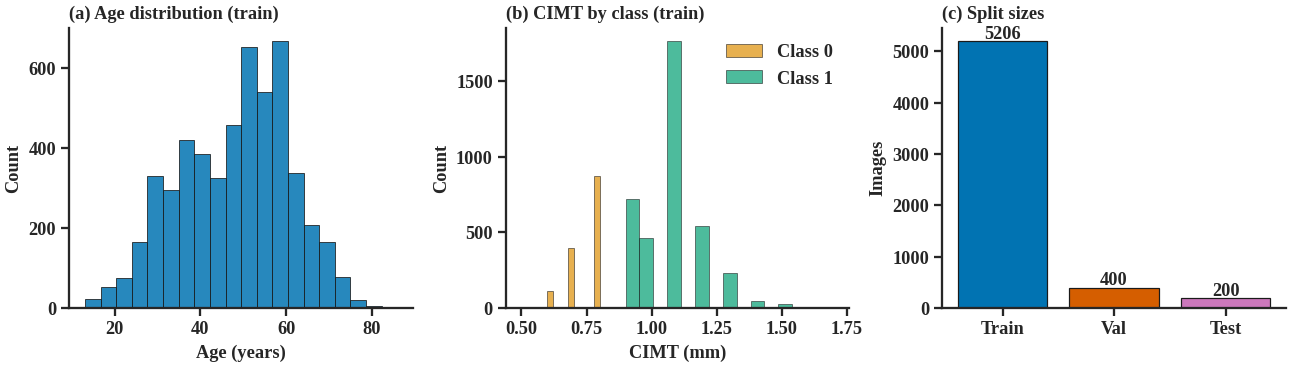

In [4]:
def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

df = pd.read_csv(CFG["csv_path"])
print("raw CSV:", df.shape)
display(df.head())

AGE_COL = "True_age" if "True_age" in df.columns else "age"
NUM_COLS = ["thickness", "label", "gender", "group", AGE_COL]
for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# ---------- data audit: NaN / inf / missing files (a NaN here silently poisons training and metrics) ----------
audit = pd.Series({**{"image_name": int(df["image_name"].isna().sum())},
                   **{c: int((df[c].isna() | np.isinf(df[c])).sum()) for c in NUM_COLS}},
                  name="rows with missing / non-finite values")
display(audit.to_frame().T)

bad = df["image_name"].isna() | df[["thickness", "label", "group"]].isna().any(axis=1) \
      | np.isinf(df[["thickness", "label", "group"]]).any(axis=1)
if bad.any():
    print(f"[FIX] dropping {int(bad.sum())} rows with missing image_name / thickness / label / group")
    df = df[~bad].reset_index(drop=True)

img_files = set(os.listdir(CFG["images_dir"])) if os.path.isdir(CFG["images_dir"]) else set()
msk_files = set(os.listdir(CFG["masks_dir"])) if os.path.isdir(CFG["masks_dir"]) else set()
assert len(img_files) > 0, f"images_dir not found or empty: {CFG['images_dir']}"
assert len(msk_files) > 0, f"masks_dir not found or empty: {CFG['masks_dir']}"
_base = df["image_name"].astype(str).map(lambda s: os.path.splitext(s)[0])
has_files = (_base + ".png").isin(img_files) & (_base + "_mask.png").isin(msk_files)
if (~has_files).any():
    print(f"[FIX] dropping {int((~has_files).sum())} rows whose image or mask file is missing")
    df = df[has_files.values].reset_index(drop=True)

df["group"] = df["group"].astype(int)
df["label"] = df["label"].astype(int)
assert set(df["group"].unique()) <= {1, 2, 3}, f"unexpected group values: {sorted(df['group'].unique())}"

# age / gender are model INPUTS: impute missing values with TRAIN statistics only (no leakage)
_tr = df["group"] == 1
for col, fill in [(AGE_COL, df.loc[_tr, AGE_COL].median()),
                  ("gender", df.loc[_tr, "gender"].mode().iloc[0])]:
    n_na = int((df[col].isna() | np.isinf(df[col])).sum())
    if n_na:
        print(f"[FIX] imputing {n_na} missing '{col}' values with the training statistic = {fill}")
        df[col] = df[col].replace([np.inf, -np.inf], np.nan).fillna(fill)
assert np.isfinite(df[NUM_COLS].values.astype(float)).all(), "non-finite values remain in the CSV"

df["patient"] = df["image_name"].apply(lambda x: get_patient_id(os.path.splitext(str(x))[0]))
train_df = df[df["group"] == 1].reset_index(drop=True)
val_df   = df[df["group"] == 2].reset_index(drop=True)
test_df  = df[df["group"] == 3].reset_index(drop=True)
assert len(train_df) and len(val_df) and len(test_df), "one of the splits is empty"

p_tr, p_va, p_te = set(train_df["patient"]), set(val_df["patient"]), set(test_df["patient"])
assert len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0, "patient leakage between splits!"
print(f"patients train/val/test = {len(p_tr)}/{len(p_va)}/{len(p_te)} | overlap tv=0 tt=0 vt=0")
print(f"images train/val/test = {len(train_df)} {len(val_df)} {len(test_df)}")

SCALER = dict(
    age_mu = float(train_df[AGE_COL].mean()),
    age_sd = float(train_df[AGE_COL].std() + 1e-8),
    t_mu   = float(train_df["thickness"].mean()),
    t_sd   = float(train_df["thickness"].std() + 1e-8),
)
print(SCALER)
print("label counts (train):", train_df["label"].value_counts().to_dict())

def _summ(split_df, name):
    n_pat = split_df["patient"].nunique()
    n_img = len(split_df)
    age_m, age_s = split_df[AGE_COL].mean(), split_df[AGE_COL].std()
    g1 = int((split_df["gender"] == 1).sum())
    c1 = int((split_df["label"] == 1).sum())
    t_m, t_s = split_df["thickness"].mean(), split_df["thickness"].std()
    return {
        "Split": name, "Patients": n_pat, "Images": n_img,
        "Age, years (mean ± SD)": f"{age_m:.1f} ± {age_s:.1f}",
        "Gender 1, n (%)": f"{g1} ({100 * g1 / max(n_img,1):.1f}%)",
        "Class 1, n (%)": f"{c1} ({100 * c1 / max(n_img,1):.1f}%)",
        "CIMT, mm (mean ± SD)": f"{t_m:.2f} ± {t_s:.2f}",
    }

tab1 = pd.DataFrame([_summ(train_df, "Training"), _summ(val_df, "Validation"),
                     _summ(test_df, "Test"), _summ(df, "Total")])
show_table(tab1, "dataset_characteristics",
           "Characteristics of the fundus-image dataset and the patient-level train / validation / test split.",
           note="Both eyes of a patient are always in the same split (verified, no patient overlap). CIMT = carotid intima-media thickness. A/V masks come from the Fundus_A and V dataset.")

# ---------- Fig. 1 Dataset overview ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(train_df[AGE_COL], bins=20, color=PAL[0], alpha=0.85, edgecolor="k", linewidth=0.6)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Count")
ttl(axes[0], "a", "Age distribution (train)")
for lab, col in [(0, PAL[1]), (1, PAL[2])]:
    sub = train_df[train_df["label"] == lab]["thickness"]
    axes[1].hist(sub, bins=15, alpha=0.7, color=col, label=CLASS_NAMES.get(lab, str(lab)), edgecolor="k", linewidth=0.5)
axes[1].set_xlabel("CIMT (mm)"); axes[1].set_ylabel("Count"); axes[1].legend(frameon=False)
ttl(axes[1], "b", "CIMT by class (train)")
sizes = [len(train_df), len(val_df), len(test_df)]
axes[2].bar(["Train", "Val", "Test"], sizes, color=[PAL[0], PAL[3], PAL[4]], edgecolor="k", linewidth=0.8)
axes[2].set_ylabel("Images")
for i, v in enumerate(sizes):
    axes[2].text(i, v + max(sizes) * 0.01, str(v), ha="center", fontweight="bold", fontsize=FS)
ttl(axes[2], "c", "Split sizes")
plt.tight_layout()
save_fig(fig, "dataset_overview",
         "Dataset overview. (a) Age distribution in the training set. (b) CIMT distribution by disease class. (c) Number of images per split.")


## 5. Dataset and data loaders (vessel + A/V multi-class mask)
Supports `{base}_av.png` (0/1/2), `{base}_artery.png`+`{base}_vein.png`, or `artery/`+`vein/` subfolders.


In [5]:
def _load_av_mask(av_dir, base, size):
    """Return (H,W) int64 with 0=bg, 1=artery, 2=vein. None if not found."""
    if av_dir is None or not os.path.isdir(av_dir):
        return None
    candidates = [
        os.path.join(av_dir, base + "_av.png"),
        os.path.join(av_dir, base + "_AV.png"),
        os.path.join(av_dir, base + ".png"),
    ]
    for p in candidates:
        if os.path.isfile(p):
            im = Image.open(p)
            if im.mode == "P":                                   # palette image: raw indices 0/1/2 are the labels
                idx = np.asarray(im.resize((size, size), Image.NEAREST))
                if idx.max() <= 2:
                    return idx.astype(np.int64)
                im = im.convert("RGB")
            elif im.mode not in ("L", "RGB"):
                im = im.convert("RGB")
            m = np.asarray(im.resize((size, size), Image.NEAREST))
            if m.ndim == 3:
                r, g, b = m[..., 0].astype(float), m[..., 1].astype(float), m[..., 2].astype(float)
                out = np.zeros(m.shape[:2], dtype=np.int64)
                out[(r > 120) & (r > g) & (r > b)] = 1   # red-ish -> artery
                out[(b > 120) & (b > r) & (b > g)] = 2   # blue-ish -> vein
                return out
            m = m.astype(np.float32)
            if m.max() > 2:
                m = m / 255.0
                out = np.zeros_like(m, dtype=np.int64)
                out[m > 0.6] = 2
                out[(m > 0.2) & (m <= 0.6)] = 1
                return out
            return np.clip(np.rint(m), 0, 2).astype(np.int64)    # already 0/1/2 label map
    art_p = [os.path.join(av_dir, base + "_artery.png"),
             os.path.join(av_dir, "artery", base + ".png"),
             os.path.join(av_dir, "Artery", base + ".png")]
    vein_p = [os.path.join(av_dir, base + "_vein.png"),
              os.path.join(av_dir, "vein", base + ".png"),
              os.path.join(av_dir, "Vein", base + ".png")]
    art = next((p for p in art_p if os.path.isfile(p)), None)
    vein = next((p for p in vein_p if os.path.isfile(p)), None)
    if art is None and vein is None:
        return None
    out = np.zeros((size, size), dtype=np.int64)
    if art is not None:
        a = np.asarray(Image.open(art).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[a] = 1
    if vein is not None:
        v = np.asarray(Image.open(vein).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[v] = 2
    return out


class MTDataset(Dataset):
    def __init__(self, images_dir, masks_dir, av_masks_dir, df, img_size=512, augment=False, scaler=None, probe=True):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.av_masks_dir = av_masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment
        self.sc = scaler if scaler is not None else SCALER
        if probe:
            n_probe = min(80, len(self.df))
            n_av = 0
            for i in range(n_probe):
                base = os.path.splitext(str(self.df.iloc[i]["image_name"]))[0]
                if _load_av_mask(av_masks_dir, base, 64) is not None:
                    n_av += 1
            print(f"  A/V mask probe (first {n_probe}): {n_av}/{n_probe} found")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(str(row["image_name"]))[0]
        s = self.img_size
        img_path = os.path.join(self.images_dir, base + ".png")
        mask_path = os.path.join(self.masks_dir, base + "_mask.png")
        img = Image.open(img_path).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(mask_path).convert("L").resize((s, s), Image.NEAREST)
        av = _load_av_mask(self.av_masks_dir, base, s)

        if self.augment:
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
                if av is not None:
                    av = np.ascontiguousarray(np.fliplr(av))
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img = img.rotate(a, resample=Image.BILINEAR)
                mask = mask.rotate(a, resample=Image.NEAREST)
                if av is not None:
                    av = np.asarray(Image.fromarray(av.astype(np.uint8)).rotate(a, resample=Image.NEAREST))

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if av is None:
            av_np = np.zeros((s, s), dtype=np.int64)
            has_av = 0.0
        else:
            av_np = np.clip(av, 0, 2).astype(np.int64)
            has_av = 1.0

        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        age = (float(row[AGE_COL]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (
            torch.from_numpy(img_np).permute(2, 0, 1).contiguous(),
            torch.from_numpy(mask_np).unsqueeze(0),
            torch.from_numpy(av_np).long(),
            torch.tensor(has_av, dtype=torch.float32),
            clin,
            torch.tensor(float(row["label"]), dtype=torch.float32),
            torch.tensor(thick, dtype=torch.float32),
        )


def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


def make_ds_loader(df, augment, shuffle, img_size=None, probe=True):
    ds = MTDataset(CFG["images_dir"], CFG["masks_dir"], CFG["av_masks_dir"],
                   df, img_size or CFG["img_size"], augment, SCALER, probe=probe)
    g = torch.Generator()
    g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment,
                    num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                    worker_init_fn=_seed_worker, generator=g)
    return ds, dl

train_ds, train_loader = make_ds_loader(train_df, True, True)
val_ds,   val_loader   = make_ds_loader(val_df, False, False, probe=False)
test_ds,  test_loader  = make_ds_loader(test_df, False, False, probe=False)
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

# ---------- sanity check of the A/V labels (all-zero A/V masks would make Task 4 meaningless) ----------
_cnt = np.zeros(3, dtype=np.float64)
_n_chk = min(20, len(train_ds))
for _i in range(_n_chk):
    _, _m, _av, _has, _, _, _ = train_ds[_i]
    _cnt += np.bincount(_av.numpy().ravel(), minlength=3)[:3]
_share = 100 * _cnt / max(_cnt.sum(), 1)
print(f"A/V pixel share over {_n_chk} train images -> background {_share[0]:.1f}% | artery {_share[1]:.2f}% | vein {_share[2]:.2f}%")
if _share[1] + _share[2] < 0.1:
    print("[WARNING] almost no artery/vein pixels found - check CFG['av_masks_dir'] and the A/V colour coding in _load_av_mask().")


  A/V mask probe (first 80): 80/80 found
train=5206 val=400 test=200
A/V pixel share over 20 train images -> background 91.7% | artery 3.69% | vein 4.58%


## 6. Model: ResUNet++ (multi-task + A/V head)

Residual encoder–decoder with Squeeze-and-Excitation blocks, ASPP at the bridge, and attention-gated skip connections (as in the classic ResUNet++ design).


In [6]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        mid = max(channels // reduction, 4)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, mid),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels),
            nn.Sigmoid(),
        )
    def forward(self, x):
        w = self.fc(x).unsqueeze(-1).unsqueeze(-1)
        return x * w


class ResidualConv(nn.Module):
    """Two 3x3 convs (pre-activation BN-ReLU-Conv) with optional residual addition and optional SE."""
    def __init__(self, in_ch, out_ch, dropout_p=0.0, stride=1, use_res=True, use_se=True):
        super().__init__()
        self.use_res = use_res
        self.conv1 = nn.Sequential(
            nn.BatchNorm2d(in_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
        )
        self.conv2 = nn.Sequential(
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
        )
        self.se = SEBlock(out_ch) if use_se else nn.Identity()
        self.dropout = nn.Dropout2d(dropout_p) if dropout_p > 0 else nn.Identity()
        if use_res:
            self.skip = (nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False)
                         if (in_ch != out_ch or stride != 1) else nn.Identity())

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.se(out)
        out = self.dropout(out)
        return out + self.skip(x) if self.use_res else out


class ASPP(nn.Module):
    """Atrous Spatial Pyramid Pooling (bridge)."""
    def __init__(self, in_ch, out_ch, rates=(6, 12, 18)):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )
        ])
        for r in rates:
            self.branches.append(nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=r, dilation=r, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            ))
        self.branches.append(nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.ReLU(inplace=True),       # no BatchNorm on the 1x1 pooled map (unstable / errors with tiny batches)
        ))
        self.project = nn.Sequential(
            nn.Conv2d(out_ch * (2 + len(rates)), out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
        )

    def forward(self, x):
        size = x.shape[-2:]
        outs = []
        for i, b in enumerate(self.branches):
            o = b(x)
            if i == len(self.branches) - 1:  # global pool branch
                o = F.interpolate(o, size=size, mode="bilinear", align_corners=False)
            outs.append(o)
        return self.project(torch.cat(outs, dim=1))


class AttentionBlock(nn.Module):
    """Attention gate for skip connections (ResUNet++ style)."""
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, 1, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, 1, bias=True),
            nn.BatchNorm2d(F_int),
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, 1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid(),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        if g1.shape[-2:] != x1.shape[-2:]:
            g1 = F.interpolate(g1, size=x1.shape[-2:], mode="bilinear", align_corners=False)
        psi = self.psi(self.relu(g1 + x1))
        if psi.shape[-2:] != x.shape[-2:]:
            psi = F.interpolate(psi, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return x * psi, psi


class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x):
        return self.net(x)


class ResUNetPlusPlusMultiTask(nn.Module):
    """
    ResUNet++ multi-task network:
      - Residual + SE encoder stages
      - ASPP bridge
      - Attention-gated decoder
      - Binary vessel head (topology losses applied outside)
      - 3-class Artery/Vein/Background head
      - Clinical MLP + shared FC -> classification & regression heads
    The use_res / use_se / use_aspp / use_att / use_clinical switches exist for the ablation study
    (all True = the proposed model).
    """
    def __init__(self, in_ch=3, base_ch=16, clinical_dim=2, clinical_hidden=32,
                 fc_dim=128, use_clinical=True, n_av_classes=3,
                 use_res=True, use_se=True, use_aspp=True, use_att=True):
        super().__init__()
        self.use_clinical = use_clinical
        self.clinical_hidden = clinical_hidden
        self.n_av_classes = n_av_classes
        c = [base_ch * (2 ** i) for i in range(5)]  # 16,32,64,128,256
        self.c = c
        R = dict(use_res=use_res, use_se=use_se)

        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, c[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(c[0]),
            nn.ReLU(inplace=True),
            nn.Conv2d(c[0], c[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(c[0]),
            nn.ReLU(inplace=True),
        )

        self.enc1 = ResidualConv(c[0], c[0], dropout_p=0.05, **R)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ResidualConv(c[0], c[1], dropout_p=0.1, **R)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ResidualConv(c[1], c[2], dropout_p=0.15, **R)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ResidualConv(c[2], c[3], dropout_p=0.2, **R)
        self.pool4 = nn.MaxPool2d(2)

        bridge = [ResidualConv(c[3], c[4], dropout_p=0.25, **R)]
        if use_aspp:
            bridge.append(ASPP(c[4], c[4]))
        self.bridge = nn.Sequential(*bridge)

        self.att4 = AttentionBlock(c[4], c[3], c[3] // 2) if use_att else None
        self.up4 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.dec4 = ResidualConv(c[4] + c[3], c[3], dropout_p=0.2, **R)

        self.att3 = AttentionBlock(c[3], c[2], c[2] // 2) if use_att else None
        self.up3 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.dec3 = ResidualConv(c[3] + c[2], c[2], dropout_p=0.15, **R)

        self.att2 = AttentionBlock(c[2], c[1], c[1] // 2) if use_att else None
        self.up2 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.dec2 = ResidualConv(c[2] + c[1], c[1], dropout_p=0.1, **R)

        self.att1 = AttentionBlock(c[1], c[0], c[0] // 2) if use_att else None
        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.dec1 = ResidualConv(c[1] + c[0], c[0], dropout_p=0.05, **R)

        self.seg_head = nn.Sequential(
            nn.Conv2d(c[0], c[0], 3, padding=1),
            nn.BatchNorm2d(c[0]),
            nn.ReLU(inplace=True),
            nn.Conv2d(c[0], 1, 1),
        )
        self.av_head = nn.Sequential(
            nn.Conv2d(c[0], c[0], 3, padding=1),
            nn.BatchNorm2d(c[0]),
            nn.ReLU(inplace=True),
            nn.Conv2d(c[0], n_av_classes, 1),
        )

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(
            nn.Linear(c[4] + clinical_hidden, fc_dim),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Dropout(0.3),
        )
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    @staticmethod
    def _gate(att, g, x):
        if att is None:
            return x, None
        return att(g, x)

    def forward(self, x, clinical=None, **kwargs):
        s0 = self.stem(x)
        e1 = self.enc1(s0)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b  = self.bridge(self.pool4(e4))

        atts = {}
        a4, atts[3] = self._gate(self.att4, b, e4)
        d4 = self.dec4(torch.cat([self.up4(b), a4], dim=1))
        a3, atts[2] = self._gate(self.att3, d4, e3)
        d3 = self.dec3(torch.cat([self.up3(d4), a3], dim=1))
        a2, atts[1] = self._gate(self.att2, d3, e2)
        d2 = self.dec2(torch.cat([self.up2(d3), a2], dim=1))
        a1, atts[0] = self._gate(self.att1, d2, e1)
        d1 = self.dec1(torch.cat([self.up1(d2), a1], dim=1))

        seg = self.seg_head(d1)
        av  = self.av_head(d1)

        cls_logit = reg_pred = None
        if clinical is not None:
            pooled = self.gap(b).flatten(1)
            cf = (self.clinical_mlp(clinical) if self.use_clinical
                  else pooled.new_zeros(pooled.shape[0], self.clinical_hidden))
            h = self.shared_fc(torch.cat([pooled, cf], 1))
            cls_logit = self.cls_head(h).squeeze(1)
            reg_pred  = self.reg_head(h).squeeze(1)

        return dict(seg=seg, av=av, deep=[seg], cls=cls_logit, reg=reg_pred, att={k: v for k, v in atts.items() if v is not None})


def count_params(m):
    return sum(p.numel() for p in m.parameters())

model = ResUNetPlusPlusMultiTask(base_ch=CFG["base_ch"]).to(device)
n_params = count_params(model)
print(f"Total parameters: {n_params:,}")
with torch.no_grad():
    model.eval()
    o = model(torch.randn(2, 3, min(CFG["img_size"], 128), min(CFG["img_size"], 128), device=device),
              torch.randn(2, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| av:", tuple(o["av"].shape),
      "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))
assert all(torch.isfinite(v).all() for v in (o["seg"], o["av"], o["cls"], o["reg"])), "non-finite output at initialisation"


Total parameters: 4,400,354
seg: (2, 1, 128, 128) | av: (2, 3, 128, 128) | cls: (2,) | reg: (2,)


## 7. Architecture figure (Fig. 2)


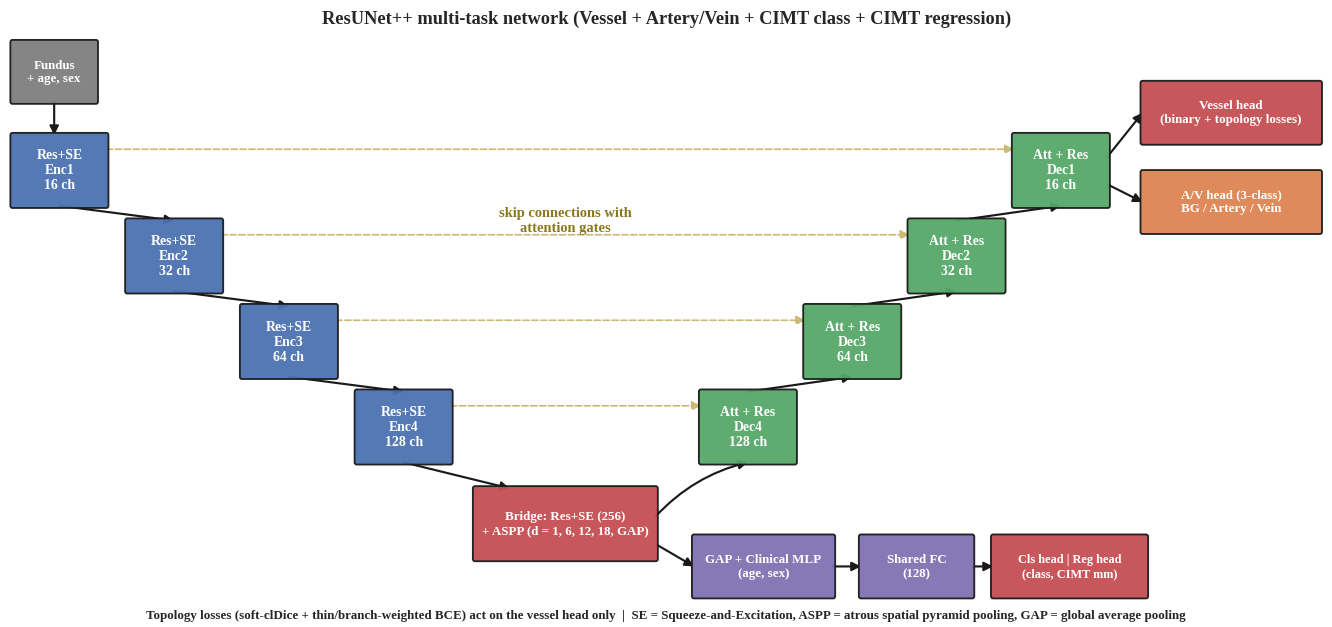

In [7]:
def draw_architecture(use_att=True):
    fig, ax = plt.subplots(figsize=(15.5, 7.2))
    ax.set_xlim(0, 19); ax.set_ylim(0, 8.2); ax.axis("off")
    C = dict(enc="#4C72B0", aspp="#C44E52", dec="#55A868", vessel="#C44E52",
             av="#DD8452", clin="#8172B2", att="#CCB974", inp="#7f7f7f")
    def box(x, y, w, h, txt, fc, fs=9):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03", fc=fc, ec="k", lw=1.2, alpha=0.95, zorder=3))
        ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=fs, fontweight="bold", color="white", fontfamily="serif", zorder=4)
    def arrow(p, q, style="-|>", ls="-", rad=0.0, color="k", lw=1.4):
        ax.annotate("", xy=q, xytext=p, zorder=2,
                    arrowprops=dict(arrowstyle=style, ls=ls, lw=lw, color=color, shrinkA=0, shrinkB=0,
                                    connectionstyle=f"arc3,rad={rad}"))
    w, h = 1.35, 0.95
    # input
    box(0.1, 6.9, 1.2, 0.8, "Fundus\n+ age, sex", C["inp"], 8.5)
    # encoder (descending), decoder (ascending)
    ex = [0.1, 1.75, 3.4, 5.05]; ey = [5.5, 4.35, 3.2, 2.05]
    chs = [16, 32, 64, 128]
    for i in range(4):
        box(ex[i], ey[i], w, h, f"Res+SE\nEnc{i+1}\n{chs[i]} ch", C["enc"])
    arrow((0.7, 6.9), (0.7, 6.45))
    for i in range(3):
        arrow((ex[i] + w/2, ey[i]), (ex[i+1] + w/2, ey[i+1] + h), color="k")   # (down: pooling)
    # bridge
    bx, by = 6.75, 0.75
    box(bx, by, 2.6, h, "Bridge: Res+SE (256)\n+ ASPP (d = 1, 6, 12, 18, GAP)", C["aspp"], 8.5)
    arrow((ex[3] + w/2, ey[3]), (bx + 0.5, by + h))
    # decoder
    dx = [10.0, 11.5, 13.0, 14.5]; dy = [2.05, 3.2, 4.35, 5.5]; dch = [128, 64, 32, 16]
    # dec1 is the shallowest (16 ch) -> highest; order deepest to shallowest left->right
    for j in range(4):
        lab = 4 - j
        box(dx[j], dy[j], w, h, f"{'Att + ' if use_att else ''}Res\nDec{lab}\n{dch[j]} ch", C["dec"])
    arrow((bx + 2.6, by + h/2 + 0.1), (dx[0] + w/2, dy[0]), rad=-0.15)
    for j in range(3):
        arrow((dx[j] + w/2, dy[j] + h), (dx[j+1] + w/2, dy[j+1]))
    # skip connections (encoder -> decoder) with attention gates
    for i in range(4):
        j = 3 - i
        y_line = ey[i] + h + 0.28 + (3 - i) * 0.0
        ax.annotate("", xy=(dx[j], dy[j] + h*0.8), xytext=(ex[i] + w, ey[i] + h*0.8), zorder=1,
                    arrowprops=dict(arrowstyle="-|>", ls="--", lw=1.1, color=C["att"] if use_att else "gray",
                                    connectionstyle="arc3,rad=-0.0", shrinkA=0, shrinkB=0))
    ax.text(8.05, 5.15, "skip connections" + (" with\nattention gates" if use_att else ""), ha="center", fontsize=9.5,
            fontweight="bold", fontfamily="serif", color="#8a7a1f" if use_att else "gray")
    # heads (right of Dec1)
    box(16.35, 6.35, 2.55, 0.8, "Vessel head\n(binary + topology losses)", C["vessel"], 8.5)
    box(16.35, 5.15, 2.55, 0.8, "A/V head (3-class)\nBG / Artery / Vein", C["av"], 8.5)
    arrow((dx[3] + w, dy[3] + h*0.7), (16.35, 6.75))
    arrow((dx[3] + w, dy[3] + h*0.3), (16.35, 5.55))
    # clinical branch
    box(9.9, 0.25, 2.0, 0.8, "GAP + Clinical MLP\n(age, sex)", C["clin"], 8.5)
    box(12.3, 0.25, 1.6, 0.8, "Shared FC\n(128)", C["clin"], 8.5)
    box(14.2, 0.25, 2.2, 0.8, "Cls head | Reg head\n(class, CIMT mm)", C["vessel"], 8)
    arrow((bx + 2.6, by + 0.2), (9.9, 0.65), rad=0.0)
    arrow((11.9, 0.65), (12.3, 0.65)); arrow((13.9, 0.65), (14.2, 0.65))
    ax.text(9.5, 7.95, "ResUNet++ multi-task network (Vessel + Artery/Vein + CIMT class + CIMT regression)",
            ha="center", fontsize=FS, fontweight="bold", fontfamily="serif")
    ax.text(9.5, -0.05, "Topology losses (soft-clDice + thin/branch-weighted BCE) act on the vessel head only  |  SE = Squeeze-and-Excitation, ASPP = atrous spatial pyramid pooling, GAP = global average pooling",
            ha="center", fontsize=8.5, fontweight="bold", fontfamily="serif")
    save_fig(fig, "architecture",
             "Network architecture. ResUNet++ encoder–decoder with residual blocks, Squeeze-and-Excitation, "
             "ASPP bridge and attention-gated skips produces a binary vessel mask "
             "(Task 3, topology-aware) and a 3-class Artery/Vein/Background mask (Task 4). "
             "Global features + clinical variables feed the classification and regression heads (Tasks 1–2).")

draw_architecture()


## 8. Parameter count (merged into Table 3)


In [8]:
def component_params(m):
    def P(*mods):
        return sum(p.numel() for mod in mods if mod is not None for p in mod.parameters())
    parts = [
        ("Stem + Encoder (Res+SE)", P(m.stem, m.enc1, m.enc2, m.enc3, m.enc4)),
        ("Bridge (Res + ASPP)", P(m.bridge)),
        ("Attention gates", P(m.att1, m.att2, m.att3, m.att4)),
        ("Decoder (Res)", P(m.dec1, m.dec2, m.dec3, m.dec4)),
        ("Vessel head", P(m.seg_head)),
        ("A/V head", P(m.av_head)),
        ("Clinical + shared FC + cls/reg", P(m.clinical_mlp, m.shared_fc, m.cls_head, m.reg_head)),
    ]
    return pd.DataFrame(parts, columns=["Component", "Parameters"])

cp = component_params(model)
assert int(cp["Parameters"].sum()) == n_params, "component breakdown does not add up to the total"
cp["Parameters (M)"] = (cp["Parameters"] / 1e6).round(4)
display(cp[["Component", "Parameters (M)"]])      # merged into Table 3 below
print("Total parameters:", f"{n_params:,}")


,Component,Parameters (M)
0,Stem + Encoder (Res+SE),0.3124
1,Bridge (Res + ASPP),3.1575
2,Attention gates,0.0335
3,Decoder (Res),0.8538
4,Vessel head,0.0024
5,A/V head,0.0024
6,Clinical + shared FC + cls/reg,0.0384


Total parameters: 4,400,354


## 9. Loss (vessel topology + multi-class A/V) and metrics


In [9]:
# NOTE: every loss below runs in float32. The fp16 version of the focal loss computed
# log(1 - p) with p rounded to exactly 1.0, giving 0 * (-inf) = NaN, which poisoned the training / validation metrics.

class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, t):
        p = torch.sigmoid(logits.float()).flatten(1)
        t = t.float().flatten(1)
        inter = (p * t).sum(1)
        return 1 - ((2 * inter + self.smooth) / (p.sum(1) + t.sum(1) + self.smooth)).mean()


class FocalLoss(nn.Module):
    """Binary focal loss from logits, numerically stable (log-sigmoid, no clamp, no log(0))."""
    def __init__(self, alpha=0.8, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, t):
        x, t = logits.float(), t.float()
        logp, log1mp = F.logsigmoid(x), F.logsigmoid(-x)
        p = torch.exp(logp)
        pos = -self.alpha * (1 - p) ** self.gamma * t * logp
        neg = -(1 - self.alpha) * p ** self.gamma * (1 - t) * log1mp
        return (pos + neg).mean()


def _soft_erode(x):
    p1 = -F.max_pool2d(-x, (3, 1), 1, (1, 0))
    p2 = -F.max_pool2d(-x, (1, 3), 1, (0, 1))
    return torch.min(p1, p2)

def _soft_dilate(x):
    return F.max_pool2d(x, 3, 1, 1)

def _soft_open(x):
    return _soft_dilate(_soft_erode(x))

def soft_skel(x, iters=10):
    x1 = _soft_open(x)
    skel = F.relu(x - x1)
    for _ in range(iters):
        x = _soft_erode(x)
        x1 = _soft_open(x)
        delta = F.relu(x - x1)
        skel = skel + F.relu(delta - skel * delta)
    return skel


class SoftclDiceLoss(nn.Module):
    def __init__(self, iters=10, smooth=1.0):
        super().__init__()
        self.iters, self.s = iters, smooth
    def forward(self, logits, t):
        p = torch.sigmoid(logits.float())
        t = t.float()
        sp = soft_skel(p, self.iters)
        with torch.no_grad():
            st = soft_skel(t, self.iters)
        tprec = ((sp * t).flatten(1).sum(1) + self.s) / (sp.flatten(1).sum(1) + self.s)
        tsens = ((st * p).flatten(1).sum(1) + self.s) / (st.flatten(1).sum(1) + self.s)
        return (1 - 2 * tprec * tsens / (tprec + tsens + 1e-8)).mean()


class TopoWeightedBCE(nn.Module):
    def __init__(self, iters=10, thin_boost=2.0, branch_boost=4.0):
        super().__init__()
        self.iters, self.tb, self.bb = iters, thin_boost, branch_boost
    @torch.no_grad()
    def weights(self, t):
        sk = (soft_skel(t, self.iters) > 0.1).float()
        thin = (F.avg_pool2d(t, 5, 1, 2) < 0.35).float() * t
        nb = F.conv2d(sk, torch.ones(1, 1, 3, 3, device=sk.device, dtype=sk.dtype), padding=1)
        branch = ((nb >= 4) & (sk > 0)).float()
        return torch.ones_like(t) + self.tb * thin + self.bb * branch
    def forward(self, logits, t):
        t = t.float()
        w = self.weights(t)
        return F.binary_cross_entropy_with_logits(logits.float(), t, weight=w)


class MultiClassDiceLoss(nn.Module):
    def __init__(self, n_classes=3, smooth=1.0):
        super().__init__()
        self.n, self.s = n_classes, smooth
    def forward(self, logits, target):
        p = F.softmax(logits.float(), dim=1)
        loss = 0.0
        for c in range(self.n):
            pc = p[:, c]
            tc = (target == c).float()
            inter = (pc * tc).sum(dim=(1, 2))
            union = pc.sum(dim=(1, 2)) + tc.sum(dim=(1, 2))
            loss = loss + (1 - (2 * inter + self.s) / (union + self.s)).mean()
        return loss / self.n


class MultiTaskLoss(nn.Module):
    def __init__(self, lam=0.5, w_seg=1.0, w_cls=1.0, w_reg=1.0, w_av=1.0,
                 pos_weight=None, cl_iters=10, thin_boost=2.0, branch_boost=4.0,
                 w_cl=0.5, w_wb=0.5):
        super().__init__()
        self.lam = lam
        self.w_seg, self.w_cls, self.w_reg, self.w_av = w_seg, w_cls, w_reg, w_av
        self.w_cl, self.w_wb = w_cl, w_wb
        self.dice = DiceLoss()
        self.focal = FocalLoss()
        self.cldice = SoftclDiceLoss(iters=cl_iters)
        self.wbce = TopoWeightedBCE(iters=cl_iters, thin_boost=thin_boost, branch_boost=branch_boost)
        self.av_dice = MultiClassDiceLoss(n_classes=3)
        self.ce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        self.mse = nn.MSELoss()
        self.ce_av = nn.CrossEntropyLoss()

    def forward(self, out, masks, labels, thick, av_masks=None, has_av=None):
        with torch.autocast(device_type="cuda", enabled=False):          # force fp32 for all loss maths
            seg_logits = out["seg"].float()
            masks = masks.float()
            zero = seg_logits.new_zeros(())

            l_seg = zero
            if self.w_seg > 0:
                l_seg = self.dice(seg_logits, masks) + self.lam * self.focal(seg_logits, masks)
                if self.w_cl > 0:
                    l_seg = l_seg + self.w_cl * self.cldice(seg_logits, masks)
                if self.w_wb > 0:
                    l_seg = l_seg + self.w_wb * self.wbce(seg_logits, masks)

            l_cls = self.ce(out["cls"].float(), labels.float()) if (self.w_cls > 0 and out["cls"] is not None) else zero
            l_reg = self.mse(out["reg"].float(), thick.float()) if (self.w_reg > 0 and out["reg"] is not None) else zero

            l_av = zero
            if self.w_av > 0 and av_masks is not None and out.get("av") is not None and has_av is not None:
                valid = has_av > 0.5
                if bool(valid.any()):
                    av_logits = out["av"].float()[valid]
                    av_tgt = av_masks[valid]
                    l_av = self.av_dice(av_logits, av_tgt) + self.ce_av(av_logits, av_tgt)

            total = (self.w_seg * l_seg + self.w_cls * l_cls + self.w_reg * l_reg + self.w_av * l_av)
        return total, dict(seg=float(l_seg.detach()), cls=float(l_cls.detach()),
                           reg=float(l_reg.detach()), av=float(l_av.detach()))


pos = (train_df["label"] == 1).sum()
neg = (train_df["label"] == 0).sum()
pos_weight = torch.tensor([neg / max(pos, 1)], device=device, dtype=torch.float32)

def build_criterion(**over):
    kw = dict(lam=CFG["lam"], w_seg=CFG["w_seg"], w_cls=CFG["w_cls"], w_reg=CFG["w_reg"], w_av=CFG["w_av"],
              pos_weight=pos_weight, cl_iters=CFG["cl_iters"], thin_boost=CFG["thin_boost"],
              branch_boost=CFG["branch_boost"], w_cl=CFG["w_cl"], w_wb=CFG["w_wb"])
    kw.update(over)
    return MultiTaskLoss(**kw)

criterion = build_criterion()

# ---- unit check of the loss on extreme logits (this exact case produced NaN before the fix) ----
with torch.no_grad():
    _lg = torch.full((2, 1, 32, 32), 30.0, device=device)
    _lg[:, :, :, :16] = -30.0
    _t = torch.zeros(2, 1, 32, 32, device=device); _t[:, :, :, 8:24] = 1.0
    _o = dict(seg=_lg.half() if device.type == "cuda" else _lg,
              av=torch.randn(2, 3, 32, 32, device=device),
              cls=torch.zeros(2, device=device), reg=torch.zeros(2, device=device))
    _l, _ = criterion(_o, _t, torch.zeros(2, device=device), torch.zeros(2, device=device),
                      torch.zeros(2, 32, 32, dtype=torch.long, device=device), torch.ones(2, device=device))
assert torch.isfinite(_l), "loss is not finite on saturated logits"
print("Loss ready (vessel topology + A/V multi-class), fp32-safe. Saturated-logit check:", float(_l))


Loss ready (vessel topology + A/V multi-class), fp32-safe. Saturated-logit check: 16.668249130249023


In [10]:
def per_image_seg(logits, masks):
    p = (torch.sigmoid(logits.float()) > 0.5).float()
    t = masks.float()
    e = 1e-7
    tp = (p * t).sum(dim=(1, 2, 3))
    fp = (p * (1 - t)).sum(dim=(1, 2, 3))
    fn = ((1 - p) * t).sum(dim=(1, 2, 3))
    tn = ((1 - p) * (1 - t)).sum(dim=(1, 2, 3))
    d = dict(
        Dice=(2 * tp + e) / (2 * tp + fp + fn + e),
        IoU=(tp + e) / (tp + fp + fn + e),
        ACC=(tp + tn) / (tp + tn + fp + fn + e),
        SE=tp / (tp + fn + e),
        SP=tn / (tn + fp + e),
    )
    return {k: v.detach().cpu().numpy() for k, v in d.items()}


def per_image_av(logits, av_masks, has_av):
    """Mean of artery-Dice and vein-Dice per image (NaN when the image has no A/V mask). Vectorised."""
    pred = logits.argmax(1)
    ds = []
    for c in (1, 2):
        p = (pred == c).float()
        t = (av_masks == c).float()
        inter = (p * t).sum(dim=(1, 2))
        union = p.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
        ds.append((2 * inter + 1e-7) / (union + 1e-7))
    d = torch.stack(ds, 1).mean(1)
    d = torch.where(has_av > 0.5, d, torch.full_like(d, float("nan")))
    return d.detach().cpu().numpy().astype(np.float32)


@torch.no_grad()
def evaluate(model, loader, criterion=None, collect_pixels=False, pix_per_img=2000, amp=False):
    """Evaluation runs in fp32 by default (amp=False) so fp16 overflow can never create NaN predictions."""
    model.eval()
    seg = {k: [] for k in ["Dice", "IoU", "ACC", "SE", "SP"]}
    av_dice, cls_p, cls_t, reg_p, reg_t = [], [], [], [], []
    pix_p, pix_t = [], []
    tot, n_loss, n = 0.0, 0, 0
    for batch in loader:
        imgs, masks, av_masks, has_av, clin, labels, thick = batch
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        av_masks = av_masks.to(device, non_blocking=True)
        has_av = has_av.to(device, non_blocking=True)
        clin = clin.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        thick = thick.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(amp and USE_AMP)):
            out = model(imgs, clin)
        if criterion is not None and out["cls"] is not None:
            loss, _ = criterion(out, masks, labels, thick, av_masks, has_av)
            if torch.isfinite(loss):
                tot += loss.item() * imgs.size(0)
                n_loss += imgs.size(0)
        n += imgs.size(0)
        for k, v in per_image_seg(out["seg"], masks).items():
            seg[k].append(v)
        av_dice.append(per_image_av(out["av"].float(), av_masks, has_av))
        if out["cls"] is not None:
            cls_p.append(torch.sigmoid(out["cls"].float()).cpu().numpy())
            cls_t.append(labels.cpu().numpy())
            reg_p.append(out["reg"].float().cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
            reg_t.append(thick.cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
        if collect_pixels:
            pr = torch.sigmoid(out["seg"].float()).flatten(1)
            tg = masks.flatten(1)
            idx = torch.randint(0, pr.shape[1], (pix_per_img,), device=pr.device)
            pix_p.append(pr[:, idx].cpu().numpy().ravel())
            pix_t.append(tg[:, idx].cpu().numpy().ravel())
    res = dict(
        seg={k: np.concatenate(v) for k, v in seg.items()},
        av_dice=np.concatenate(av_dice),
        loss=(tot / n_loss) if n_loss else float("nan"),
    )
    if cls_p:
        cp_, rp_ = np.concatenate(cls_p), np.concatenate(reg_p)
        bad_c, bad_r = ~np.isfinite(cp_), ~np.isfinite(rp_)
        if bad_c.any() or bad_r.any():
            print(f"  [WARN] {int(bad_c.sum())} non-finite class / {int(bad_r.sum())} non-finite CIMT predictions "
                  f"-> replaced by 0.5 / train mean (model weights or BatchNorm statistics are corrupted)")
            cp_[bad_c] = 0.5
            rp_[bad_r] = SCALER["t_mu"]
        res.update(cls_prob=cp_, cls_true=np.concatenate(cls_t), reg_pred=rp_, reg_true=np.concatenate(reg_t))
    if collect_pixels:
        res.update(pix_prob=np.concatenate(pix_p), pix_true=np.concatenate(pix_t))
    return res


def summarize(res):
    m = {f"seg_{k}": float(np.nanmean(v)) for k, v in res["seg"].items()}
    av = res["av_dice"]
    m["av_Dice"] = float(np.nanmean(av)) if np.any(~np.isnan(av)) else float("nan")
    if "cls_prob" in res:
        y, p = res["cls_true"], res["cls_prob"]
        m["cls_ACC"] = float(accuracy_score(y, p > 0.5))
        m["cls_AUC"] = float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")
        m["reg_MAE"] = float(mean_absolute_error(res["reg_true"], res["reg_pred"]))
        m["reg_RMSE"] = float(mean_squared_error(res["reg_true"], res["reg_pred"]) ** 0.5)
        m["reg_R2"] = float(r2_score(res["reg_true"], res["reg_pred"]))
    return m


## 10. Implementation details (Table 2)


In [11]:
impl = [
    ("Framework", f"PyTorch {torch.__version__}"),
    ("Hardware", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"),
    ("Input size", f'{CFG["img_size"]}×{CFG["img_size"]}'),
    ("Batch size / epochs", f'{CFG["batch_size"]} / {CFG["epochs"]}'),
    ("Optimizer", f'Adam (lr={CFG["lr"]}, wd={CFG["weight_decay"]}), ReduceLROnPlateau, grad-clip {CFG["grad_clip"]}'),
    ("Precision", "fp16 autocast forward; losses and evaluation in fp32" if USE_AMP else "fp32"),
    ("Backbone", "ResUNet++ (Residual + SE + ASPP + Attention gates)"),
    ("Loss – vessel", "Dice + λ·Focal + soft-clDice + thin/branch-weighted BCE"),
    ("Loss – A/V", "Multi-class Dice + Cross-Entropy (3 classes)"),
    ("Loss – classification", "BCEWithLogits (pos_weight from train)"),
    ("Loss – regression", "MSE on z-scored CIMT"),
    ("Topology (vessel only)", f'w_cl={CFG["w_cl"]}, w_wb={CFG["w_wb"]}, cl_iters={CFG["cl_iters"]}'),
    ("Task weights", f'seg={CFG["w_seg"]}, av={CFG["w_av"]}, cls={CFG["w_cls"]}, reg={CFG["w_reg"]}'),
    ("A/V mask source", os.path.basename(CFG["av_masks_dir"]) if CFG["av_masks_dir"] else "–"),
    ("Patient-level split", "CSV group column (verified zero overlap)"),
    ("Augmentation", "flip, ±15° rotation, Gaussian noise (train only)"),
    ("Model selection", "best validation composite score (Dice + Acc + R² + A/V Dice)"),
    ("Font / figure style", "Times New Roman 12 pt bold, 600 dpi PNG+PDF+TIFF"),
]
show_table(pd.DataFrame(impl, columns=["Item", "Setting"]), "implementation_details",
           "Implementation details of the multi-task ResUNet++ (Tasks 1–4).",
           align="left", precision=0)


Item,Setting
Framework,PyTorch 2.11.0+cu130
Hardware,Tesla T4
Input size,512×512
Batch size / epochs,8 / 30
Optimizer,"Adam (lr=0.0001, wd=1e-05), ReduceLROnPlateau, grad-clip 1.0"
Precision,fp16 autocast forward; losses and evaluation in fp32
Backbone,ResUNet++ (Residual + SE + ASPP + Attention gates)
Loss – vessel,Dice + λ·Focal + soft-clDice + thin/branch-weighted BCE
Loss – A/V,Multi-class Dice + Cross-Entropy (3 classes)
Loss – classification,BCEWithLogits (pos_weight from train)


## 11. Training


In [12]:
def sanitize_bn(model):
    """Reset BatchNorm running statistics that were corrupted by a non-finite forward pass."""
    n = 0
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and m.running_mean is not None:
            if not (torch.isfinite(m.running_mean).all() and torch.isfinite(m.running_var).all()):
                m.reset_running_stats(); n += 1
    return n

def params_finite(model):
    return all(bool(torch.isfinite(p).all()) for p in model.parameters())


def train_one_epoch(model, loader, optimizer, grad_scaler, crit):
    model.train()
    tot = seg_t = cls_t = reg_t = av_t = 0.0
    n = skipped = 0
    for batch in loader:
        imgs, masks, av_masks, has_av, clin, labels, thick = batch
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        av_masks = av_masks.to(device, non_blocking=True)
        has_av = has_av.to(device, non_blocking=True)
        clin = clin.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        thick = thick.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx():
            out = model(imgs, clin)                                   # fp16 forward
        loss, parts = crit(out, masks, labels, thick, av_masks, has_av)   # fp32 loss
        if (not torch.isfinite(loss)) or (not loss.requires_grad):
            skipped += 1                                              # never back-propagate a NaN / inf batch
            sanitize_bn(model)
            continue
        grad_scaler.scale(loss).backward()
        grad_scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        grad_scaler.step(optimizer)                                   # skipped automatically if grads are inf/NaN
        grad_scaler.update()
        b = imgs.size(0)
        n += b
        tot += loss.item() * b
        seg_t += parts["seg"] * b
        cls_t += parts["cls"] * b
        reg_t += parts["reg"] * b
        av_t += parts["av"] * b
    n = max(n, 1)
    return tot / n, seg_t / n, cls_t / n, reg_t / n, av_t / n, skipped


def fit(model, epochs, ckpt_best, train_loader_=None, val_loader_=None, criterion_=None,
        verbose=True, score_w=(1.0, 1.0, 1.0, 1.0), hist_csv=None):
    tl = train_loader if train_loader_ is None else train_loader_
    vl = val_loader if val_loader_ is None else val_loader_
    crit = criterion if criterion_ is None else criterion_
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    try:
        grad_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        grad_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_score, best_epoch, hist = -1e9, 0, []
    for epoch in range(1, epochs + 1):
        if over_budget():
            print(f"[budget] stopping at epoch {epoch - 1}: {TIME_BUDGET_H} h session budget reached")
            SKIPPED_BY_BUDGET.append(f"training epochs {epoch}-{epochs}")
            break
        t0 = time.time()
        tr_loss, tr_seg, tr_cls, tr_reg, tr_av, n_skip = train_one_epoch(model, tl, optimizer, grad_scaler, crit)
        sanitize_bn(model)
        vres = evaluate(model, vl, crit)
        vm = summarize(vres)
        if np.isfinite(vres["loss"]):
            scheduler.step(vres["loss"])
        av_score = vm.get("av_Dice", 0.0)
        if isinstance(av_score, float) and np.isnan(av_score):
            av_score = 0.0
        score = (score_w[0] * vm["seg_Dice"] + score_w[1] * vm.get("cls_ACC", 0.0) +
                 score_w[2] * max(vm.get("reg_R2", 0.0), -1.0) + score_w[3] * av_score)
        dt = time.time() - t0
        hist.append(dict(
            epoch=epoch, train_loss=tr_loss, train_seg=tr_seg, train_cls=tr_cls,
            train_reg=tr_reg, train_av=tr_av, val_loss=vres["loss"], skipped_batches=n_skip,
            lr=optimizer.param_groups[0]["lr"], time_s=dt, **vm))
        if hist_csv:
            pd.DataFrame(hist).to_csv(hist_csv, index=False)
        flag = ""
        if np.isfinite(score) and score > best_score:
            best_score, best_epoch = score, epoch
            torch.save(model.state_dict(), ckpt_best)
            flag = "  <- best"
        if verbose:
            avs = f'{vm.get("av_Dice", float("nan")):.4f}' if not np.isnan(vm.get("av_Dice", np.nan)) else "n/a"
            print(f"Ep {epoch:03d}/{epochs} ({dt:.0f}s) loss {tr_loss:.3f}/{vres['loss']:.3f} | "
                  f"Dice {vm['seg_Dice']:.4f} | A/V {avs} | cls {vm.get('cls_ACC', 0):.3f} | "
                  f"MAE {vm.get('reg_MAE', 0):.4f} R2 {vm.get('reg_R2', 0):.3f}"
                  f"{f' | skipped {n_skip} non-finite batches' if n_skip else ''}{flag}")
        if not params_finite(model):
            print("[ERROR] model weights became non-finite; restoring the best checkpoint and stopping.")
            if best_epoch > 0:
                model.load_state_dict(torch.load(ckpt_best, map_location=device))
            break
    if best_epoch == 0:                      # nothing valid was ever saved -> save the current weights
        torch.save(model.state_dict(), ckpt_best)
        best_epoch = max(len(hist), 1)
    torch.save(model.state_dict(), ckpt_best.replace("_best", "_last"))
    return pd.DataFrame(hist), best_epoch


if RUN_TRAINING:
    best_ckpt = os.path.join(CFG["out_dir"], "resunetpp_multitask_av_best.pth")
    hist_path = os.path.join(CFG["out_dir"], "resunetpp_training_history.csv")
    hist_df, best_epoch = fit(model, CFG["epochs"], best_ckpt, hist_csv=hist_path)
    hist_df.to_csv(hist_path, index=False)
else:
    best_ckpt = os.path.join(CKPT_DIR, "resunetpp_multitask_av_best.pth")
    if not os.path.isfile(best_ckpt):
        best_ckpt = os.path.join(CKPT_DIR, "resunetpp_multitask_best.pth")
    hist_path = os.path.join(CKPT_DIR, "resunetpp_training_history.csv")
    if os.path.isfile(hist_path):
        hist_df = pd.read_csv(hist_path)
        best_epoch = int(hist_df["epoch"].iloc[hist_df["seg_Dice"].values.argmax()]) if "seg_Dice" in hist_df.columns else int(hist_df["epoch"].iloc[-1])
    else:
        hist_df = pd.DataFrame([{"epoch": 1, "seg_Dice": 0.0, "time_s": 0.0}])
        best_epoch = 1
    print("RUN_TRAINING = False -> using", best_ckpt)


Ep 001/30 (484s) loss 3.923/3.573 | Dice 0.7427 | A/V 0.3776 | cls 0.752 | MAE 0.1492 R2 0.288  <- best
Ep 002/30 (411s) loss 2.725/2.597 | Dice 0.8385 | A/V 0.6243 | cls 0.777 | MAE 0.1376 R2 0.360  <- best
Ep 003/30 (411s) loss 2.081/2.080 | Dice 0.8711 | A/V 0.7235 | cls 0.785 | MAE 0.1349 R2 0.378  <- best
Ep 004/30 (412s) loss 1.739/1.839 | Dice 0.8947 | A/V 0.7754 | cls 0.780 | MAE 0.1361 R2 0.372  <- best
Ep 005/30 (412s) loss 1.567/1.711 | Dice 0.9030 | A/V 0.8094 | cls 0.785 | MAE 0.1350 R2 0.373  <- best
Ep 006/30 (411s) loss 1.470/1.711 | Dice 0.9016 | A/V 0.8300 | cls 0.785 | MAE 0.1368 R2 0.358  <- best
Ep 007/30 (412s) loss 1.419/1.618 | Dice 0.9077 | A/V 0.8437 | cls 0.785 | MAE 0.1376 R2 0.371  <- best
Ep 008/30 (412s) loss 1.388/1.577 | Dice 0.9104 | A/V 0.8565 | cls 0.782 | MAE 0.1351 R2 0.382  <- best
Ep 009/30 (412s) loss 1.361/1.591 | Dice 0.9148 | A/V 0.8663 | cls 0.782 | MAE 0.1401 R2 0.353
Ep 010/30 (412s) loss 1.345/1.565 | Dice 0.9154 | A/V 0.8733 | cls 0.782 

## 12. Model size, training summary (Table 3) and training curves (Fig. 6)


Item,Value
Parameters – Stem + Encoder (Res+SE) (M),0.3124
Parameters – Bridge (Res + ASPP) (M),3.1575
Parameters – Attention gates (M),0.0335
Parameters – Decoder (Res) (M),0.8538
Parameters – Vessel head (M),0.0024
Parameters – A/V head (M),0.0024
Parameters – Clinical + shared FC + cls/reg (M),0.0384
Parameters – total (M),4.400
Best epoch,24
Val Dice (vessel),0.9187


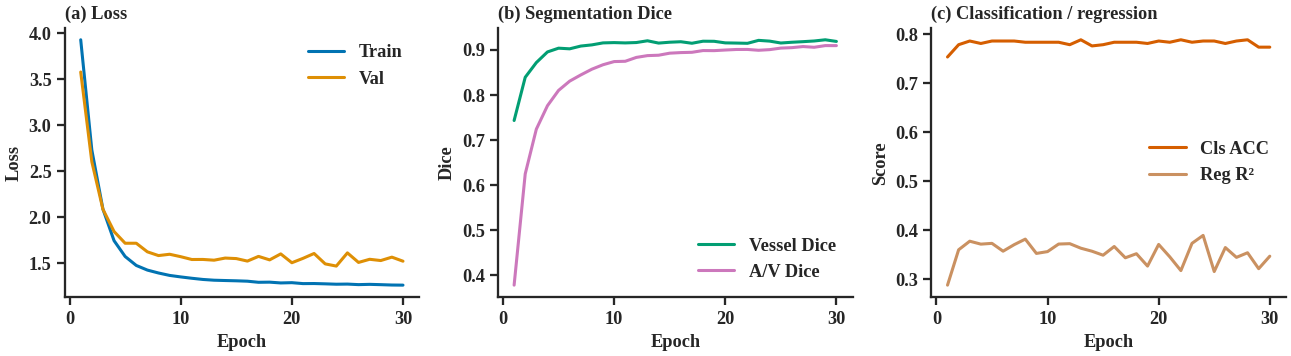

In [13]:
bh = hist_df[hist_df["epoch"] == best_epoch].iloc[0] if "epoch" in hist_df.columns else hist_df.iloc[-1]
has_t = "time_s" in hist_df.columns and hist_df["time_s"].notna().any()
comp_rows = [(f"Parameters – {r.Component} (M)", f"{r.Parameters / 1e6:.4f}") for r in cp.itertuples()]
tab3 = pd.DataFrame(comp_rows + [
    ("Parameters – total (M)", f"{n_params / 1e6:.3f}"),
    ("Best epoch", int(bh.get("epoch", best_epoch))),
    ("Val Dice (vessel)", f'{bh.get("seg_Dice", float("nan")):.4f}'),
    ("Val A/V Dice (mean art+vein)", f'{bh.get("av_Dice", float("nan")):.4f}'),
    ("Val Cls ACC", f'{bh.get("cls_ACC", float("nan")):.4f}'),
    ("Val Reg R²", f'{bh.get("reg_R2", float("nan")):.4f}'),
    ("Mean epoch time (s)", f'{hist_df["time_s"].mean():.1f}' if has_t else "–"),
], columns=["Item", "Value"])
show_table(tab3, "model_complexity",
           "Model size (parameter breakdown), best validation metrics and training summary (Tasks 1–4).",
           align="left", precision=0)

# Training curves
if len(hist_df) > 1 and "train_loss" in hist_df.columns:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    ep = hist_df["epoch"].values
    axes[0].plot(ep, hist_df["train_loss"], label="Train", color=PAL[0])
    if "val_loss" in hist_df.columns:
        axes[0].plot(ep, hist_df["val_loss"], label="Val", color=PAL[1])
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(frameon=False)
    ttl(axes[0], "a", "Loss")
    if "seg_Dice" in hist_df.columns:
        axes[1].plot(ep, hist_df["seg_Dice"], color=PAL[2], label="Vessel Dice")
        if "av_Dice" in hist_df.columns:
            axes[1].plot(ep, hist_df["av_Dice"], color=PAL[4], label="A/V Dice")
        axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Dice"); axes[1].legend(frameon=False)
        ttl(axes[1], "b", "Segmentation Dice")
    if "cls_ACC" in hist_df.columns:
        axes[2].plot(ep, hist_df["cls_ACC"], color=PAL[3], label="Cls ACC")
        if "reg_R2" in hist_df.columns:
            axes[2].plot(ep, hist_df["reg_R2"], color=PAL[5], label="Reg R²")
        axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Score"); axes[2].legend(frameon=False)
        ttl(axes[2], "c", "Classification / regression")
    plt.tight_layout()
    save_fig(fig, "training_curves",
             "Training curves of the proposed multi-task ResUNet++. (a) Train and validation loss. "
             "(b) Vessel Dice and A/V Dice on the validation set. (c) Classification accuracy and regression R².")


## 13. Test evaluation with patient-level bootstrap 95 % CI (Table 4) and performance figure (Fig. 3)


Test metrics: {'seg_Dice': 0.9185765981674194, 'seg_IoU': 0.8497377038002014, 'seg_ACC': 0.9837795495986938, 'seg_SE': 0.9494617581367493, 'seg_SP': 0.987397313117981, 'av_Dice': 0.9002934098243713, 'cls_ACC': 0.86, 'cls_AUC': 0.9433, 'reg_MAE': 0.10766860097646713, 'reg_RMSE': 0.13748581146597932, 'reg_R2': 0.48640501499176025}


Metric,Value (95 % CI where applicable)
Vessel Dice,0.9186 (0.9160–0.9210)
Vessel IoU,0.8497 (0.8457–0.8538)
Vessel Sensitivity,0.9495 (0.9467–0.9522)
Vessel Specificity,0.9874 (0.9871–0.9877)
A/V Dice (artery+vein),0.9003 (0.8957–0.9050)
Cls Accuracy,0.8600
Cls AUC,0.9433
Cls F1,0.8679
Reg MAE (mm),0.1077
Reg RMSE (mm),0.1375


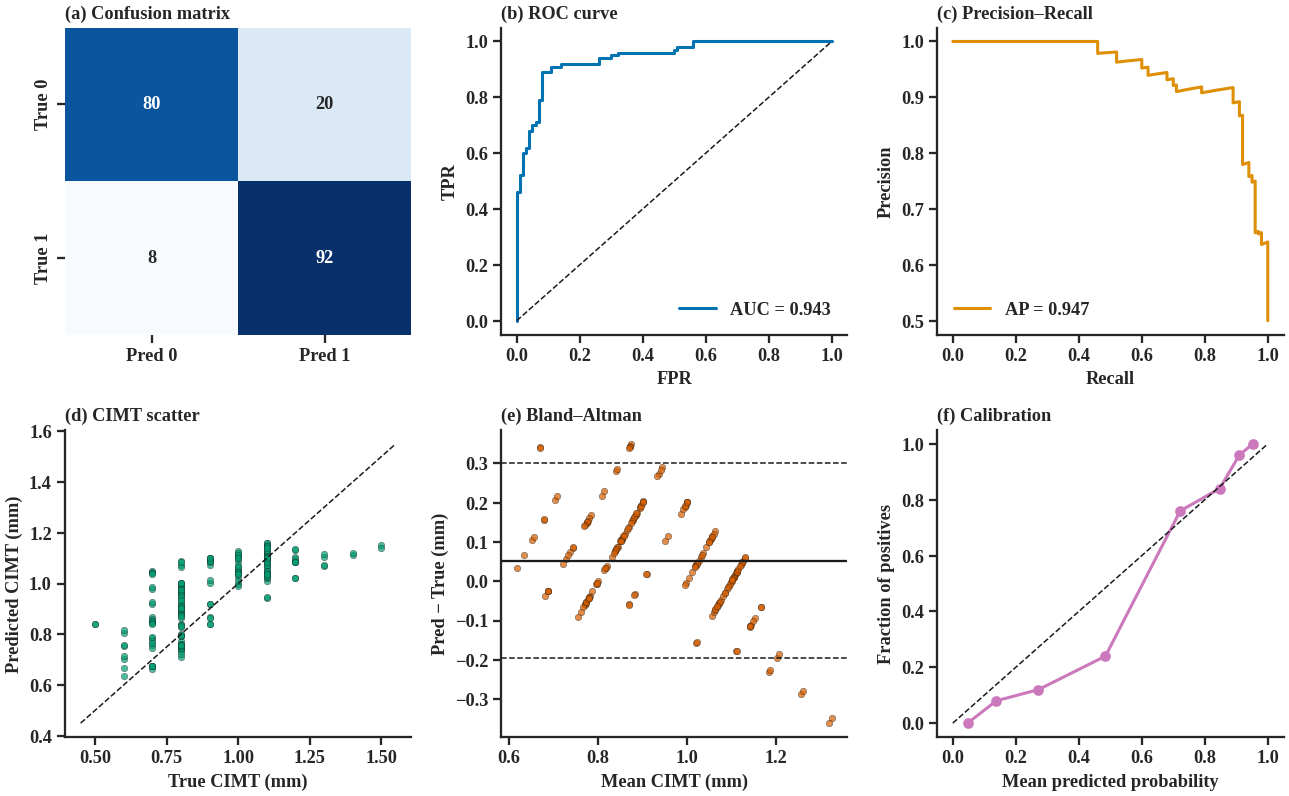

In [14]:
model.load_state_dict(torch.load(best_ckpt, map_location=device))
res = evaluate(model, test_loader, criterion)
tm = summarize(res)
print("Test metrics:", tm)

rng = np.random.default_rng(42)
pids = test_df["patient"].values
unique_p = np.unique(pids)

def boot_ci(metric_arr, n_boot=500):
    per_pat = []
    for p in unique_p:
        idx = np.where(pids == p)[0]
        per_pat.append(np.nanmean(metric_arr[idx]))
    per_pat = np.asarray(per_pat, dtype=float)
    boots = [np.nanmean(rng.choice(per_pat, size=len(per_pat), replace=True)) for _ in range(n_boot)]
    return float(np.nanmean(per_pat)), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))

rows = []
for name, arr in [
    ("Vessel Dice", res["seg"]["Dice"]),
    ("Vessel IoU", res["seg"]["IoU"]),
    ("Vessel Sensitivity", res["seg"]["SE"]),
    ("Vessel Specificity", res["seg"]["SP"]),
    ("A/V Dice (artery+vein)", res["av_dice"]),
]:
    m, lo, hi = boot_ci(arr)
    rows.append((name, fmt_ci(m, lo, hi)))
if "cls_prob" in res:
    y, p = res["cls_true"], res["cls_prob"]
    rows.append(("Cls Accuracy", f"{accuracy_score(y, p > 0.5):.4f}"))
    rows.append(("Cls AUC", f"{roc_auc_score(y, p):.4f}"))
    rows.append(("Cls F1", f"{f1_score(y, p > 0.5):.4f}"))
    rows.append(("Reg MAE (mm)", f"{mean_absolute_error(res['reg_true'], res['reg_pred']):.4f}"))
    rows.append(("Reg RMSE (mm)", f"{mean_squared_error(res['reg_true'], res['reg_pred'])**0.5:.4f}"))
    rows.append(("Reg R²", f"{r2_score(res['reg_true'], res['reg_pred']):.4f}"))

show_table(pd.DataFrame(rows, columns=["Metric", "Value (95 % CI where applicable)"]),
           "main_test_results",
           "Main test-set results of the proposed multi-task ResUNet++ (Tasks 1–4). "
           "Vessel and A/V metrics use patient-level bootstrap 95 % CI.",
           align="left")

# ---------- Fig. 3 Performance panel ----------
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
# confusion matrix
if "cls_prob" in res:
    y, p = res["cls_true"], res["cls_prob"]
    cm = confusion_matrix(y, p > 0.5)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 0],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"],
                cbar=False, annot_kws={"size": FS, "weight": "bold"})
    ttl(axes[0, 0], "a", "Confusion matrix")
    # ROC
    fpr, tpr, _ = roc_curve(y, p)
    axes[0, 1].plot(fpr, tpr, color=PAL[0], lw=2, label=f"AUC = {roc_auc_score(y, p):.3f}")
    axes[0, 1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0, 1].set_xlabel("FPR"); axes[0, 1].set_ylabel("TPR")
    axes[0, 1].legend(frameon=False); ttl(axes[0, 1], "b", "ROC curve")
    # PR
    prec, rec, _ = precision_recall_curve(y, p)
    axes[0, 2].plot(rec, prec, color=PAL[1], lw=2, label=f"AP = {average_precision_score(y, p):.3f}")
    axes[0, 2].set_xlabel("Recall"); axes[0, 2].set_ylabel("Precision")
    axes[0, 2].legend(frameon=False); ttl(axes[0, 2], "c", "Precision–Recall")
    # scatter regression
    axes[1, 0].scatter(res["reg_true"], res["reg_pred"], s=18, alpha=0.7, color=PAL[2], edgecolors="k", linewidths=0.3)
    lims = [min(res["reg_true"].min(), res["reg_pred"].min()) - 0.05,
            max(res["reg_true"].max(), res["reg_pred"].max()) + 0.05]
    axes[1, 0].plot(lims, lims, "k--", lw=1)
    axes[1, 0].set_xlabel("True CIMT (mm)"); axes[1, 0].set_ylabel("Predicted CIMT (mm)")
    ttl(axes[1, 0], "d", "CIMT scatter")
    # Bland-Altman
    mean_ba = (res["reg_true"] + res["reg_pred"]) / 2
    diff_ba = res["reg_pred"] - res["reg_true"]
    md, sd = diff_ba.mean(), diff_ba.std()
    axes[1, 1].scatter(mean_ba, diff_ba, s=18, alpha=0.7, color=PAL[3], edgecolors="k", linewidths=0.3)
    axes[1, 1].axhline(md, color="k", lw=1.5)
    axes[1, 1].axhline(md + 1.96 * sd, color="k", ls="--", lw=1)
    axes[1, 1].axhline(md - 1.96 * sd, color="k", ls="--", lw=1)
    axes[1, 1].set_xlabel("Mean CIMT (mm)"); axes[1, 1].set_ylabel("Pred − True (mm)")
    ttl(axes[1, 1], "e", "Bland–Altman")
    # calibration
    try:
        frac_pos, mean_pred = calibration_curve(y, p, n_bins=8, strategy="quantile")
        axes[1, 2].plot(mean_pred, frac_pos, "o-", color=PAL[4], lw=2)
        axes[1, 2].plot([0, 1], [0, 1], "k--", lw=1)
        axes[1, 2].set_xlabel("Mean predicted probability"); axes[1, 2].set_ylabel("Fraction of positives")
        ttl(axes[1, 2], "f", "Calibration")
    except Exception:
        axes[1, 2].axis("off")
else:
    for ax in axes.ravel():
        ax.axis("off")
plt.tight_layout()
save_fig(fig, "test_performance",
         "Test-set performance. (a) Classification confusion matrix. (b) ROC curve. (c) Precision–Recall curve. "
         "(d) CIMT regression scatter. (e) Bland–Altman plot. (f) Calibration curve.")


## 14. Subgroup analysis (Table 5)


In [15]:
with safe("subgroup analysis"):
    age_y = test_df[AGE_COL].values.astype(float)
    gend = test_df["gender"].values
    age_med = np.median(age_y)
    rows = []
    for name, mask in [
        ("All", np.ones(len(test_df), dtype=bool)),
        (f"Age ≤ {age_med:.0f}", age_y <= age_med),
        (f"Age > {age_med:.0f}", age_y > age_med),
        (GENDER_NAMES.get(0, "Gender 0"), gend == 0),
        (GENDER_NAMES.get(1, "Gender 1"), gend == 1),
    ]:
        if mask.sum() < 5:
            continue
        d = float(np.nanmean(res["seg"]["Dice"][mask]))
        av = float(np.nanmean(res["av_dice"][mask]))
        if "cls_prob" in res:
            y_s, p_s = res["cls_true"][mask], res["cls_prob"][mask]
            acc = float(accuracy_score(y_s, p_s > 0.5)) if len(y_s) else float("nan")
            auc = float(roc_auc_score(y_s, p_s)) if len(np.unique(y_s)) > 1 else float("nan")
            mae = float(mean_absolute_error(res["reg_true"][mask], res["reg_pred"][mask]))
        else:
            acc = auc = mae = float("nan")
        rows.append({"Subgroup": name, "N": int(mask.sum()),
                     "Vessel Dice": d, "A/V Dice": av,
                     "Cls ACC": acc, "Cls AUC": auc, "MAE (mm)": mae})
    tab5 = pd.DataFrame(rows)
    show_table(tab5, "subgroup_analysis",
               "Subgroup analysis on the test set (vessel Dice, A/V Dice, classification and regression).",
               precision=4)
    Q1_FLAGS["subgroup analysis"] = True


Subgroup,N,Vessel Dice,A/V Dice,Cls ACC,Cls AUC,MAE (mm)
All,200,0.9186,0.9003,0.8600,0.9433,0.1077
Age ≤ 48,100,0.9198,0.9009,0.8200,0.7699,0.1033
Age > 48,100,0.9174,0.8996,0.9000,0.8144,0.1120
Gender 0,74,0.9189,0.9001,0.8649,0.8981,0.1156
Gender 1,126,0.9184,0.9004,0.8571,0.9541,0.1030


## 15. Qualitative results – vessel + artery/vein (Fig. 4)


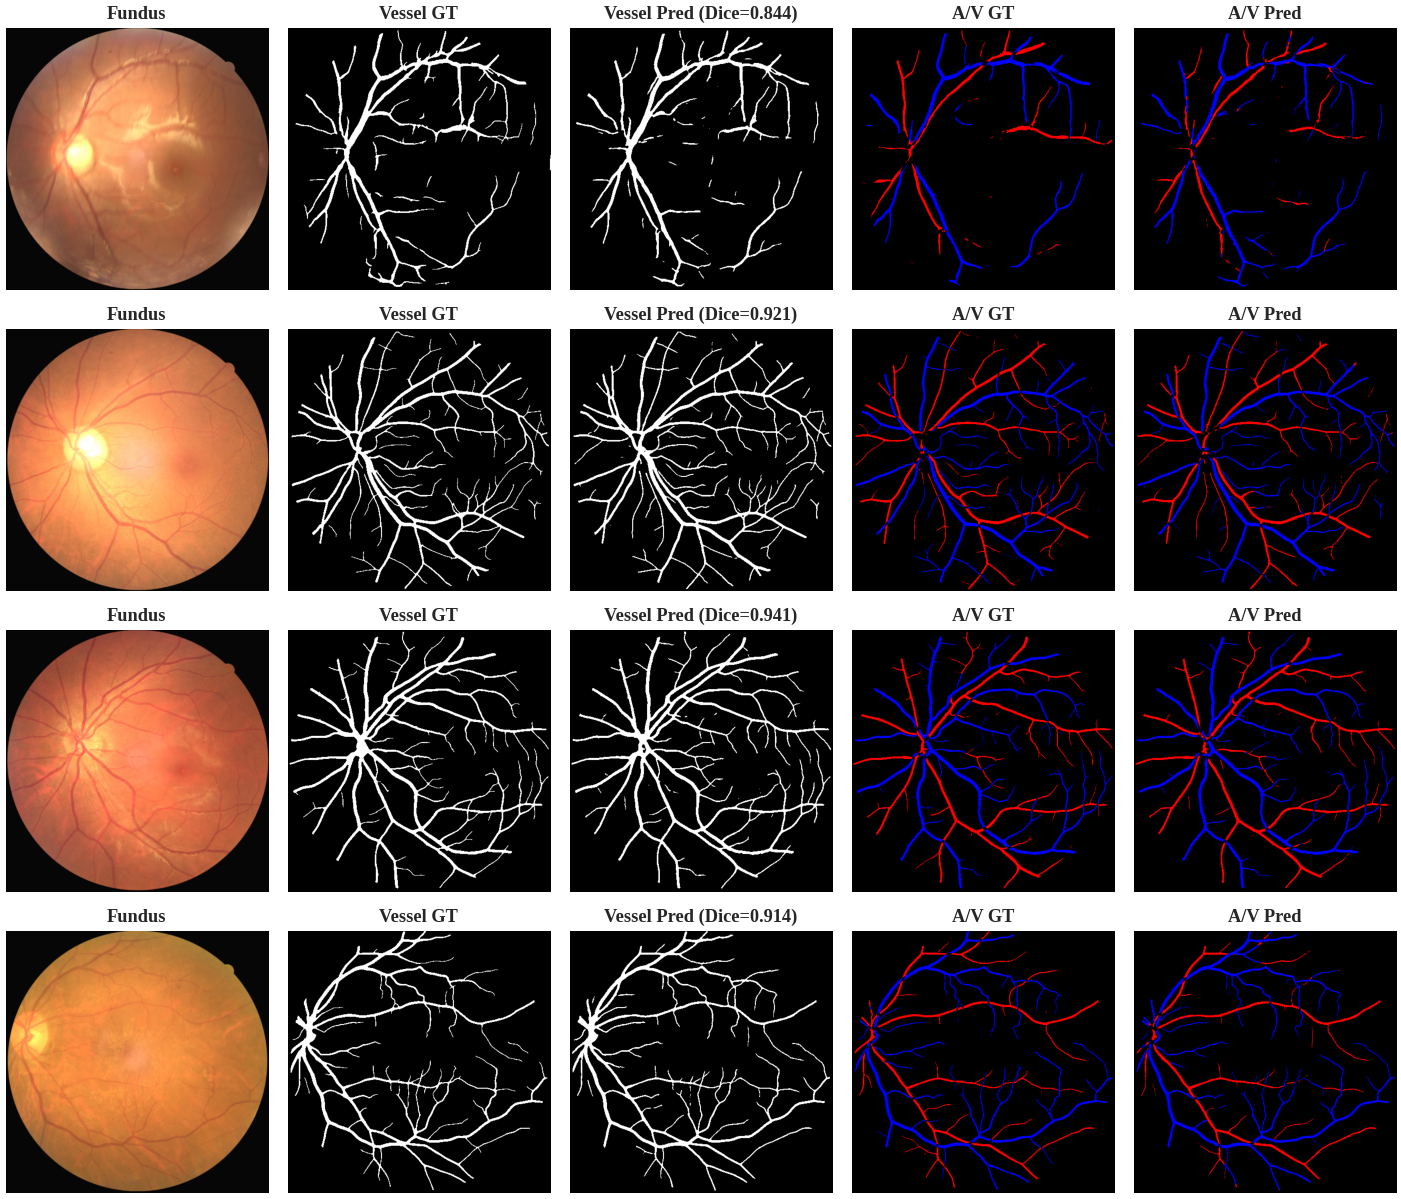

In [16]:
@torch.no_grad()
def show_qualitative(n=4):
    model.eval()
    # pick diverse examples
    dice = res["seg"]["Dice"]
    order = np.argsort(dice)
    idxs = [order[0], order[len(order)//2], order[-1]]
    if len(order) > 3:
        idxs.append(order[len(order)//4])
    idxs = idxs[:n]

    fig, axes = plt.subplots(n, 5, figsize=(13, 2.8 * n))
    if n == 1:
        axes = axes[None, :]
    for row, ii in enumerate(idxs):
        # load single sample from test set
        sample = test_ds[ii]
        img_t, mask_t, av_t, has_av_t, clin_t, _, _ = sample
        img_b = img_t.unsqueeze(0).to(device)
        clin_b = clin_t.unsqueeze(0).to(device)
        out = model(img_b, clin_b)
        seg_p = torch.sigmoid(out["seg"])[0, 0].cpu().numpy()
        av_p = out["av"][0].argmax(0).cpu().numpy()
        img_np = img_t.permute(1, 2, 0).numpy()
        mask_np = mask_t[0].numpy()
        av_np = av_t.numpy()

        def colour_av(m):
            rgb = np.zeros((*m.shape, 3), dtype=np.float32)
            rgb[m == 1, 0] = 1.0
            rgb[m == 2, 2] = 1.0
            return rgb

        axes[row, 0].imshow(np.clip(img_np, 0, 1)); axes[row, 0].set_title("Fundus", fontweight="bold"); axes[row, 0].axis("off")
        axes[row, 1].imshow(mask_np, cmap="gray"); axes[row, 1].set_title("Vessel GT", fontweight="bold"); axes[row, 1].axis("off")
        axes[row, 2].imshow(seg_p > 0.5, cmap="gray"); axes[row, 2].set_title(f"Vessel Pred (Dice={dice[ii]:.3f})", fontweight="bold"); axes[row, 2].axis("off")
        axes[row, 3].imshow(colour_av(av_np)); axes[row, 3].set_title("A/V GT", fontweight="bold"); axes[row, 3].axis("off")
        axes[row, 4].imshow(colour_av(av_p)); axes[row, 4].set_title("A/V Pred", fontweight="bold"); axes[row, 4].axis("off")
    plt.tight_layout()
    save_fig(fig, "qualitative_results",
             "Qualitative examples on the test set (worst / median / best vessel Dice). "
             "Columns: fundus, vessel GT, vessel prediction, A/V GT (red = artery, blue = vein), A/V prediction.")

show_qualitative(4)


## 16. Topology / thin-vessel / A/V metrics (Table 6, Fig. 5)


Metric,Value (95 % CI)
Vessel Dice,0.9186 (0.9162–0.9211)
Vessel IoU,0.8497 (0.8452–0.8535)
clDice (skeleton-based),0.9478 (0.9454–0.9499)
Thin-vessel recall,0.8075 (0.7945–0.8201)
A/V mean Dice (artery + vein),0.9003 (0.8957–0.9046)
Artery Dice,0.8859 (0.8792–0.8920)
Vein Dice,0.9147 (0.9104–0.9179)


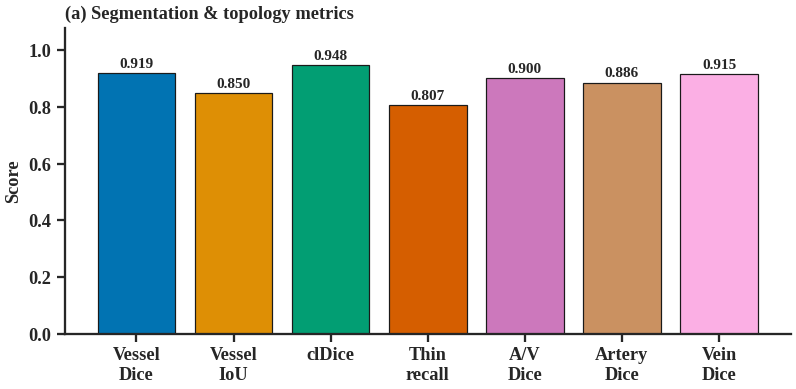

In [17]:
with safe("topology metrics"):
    from scipy import ndimage as ndi
    try:
        from skimage.morphology import skeletonize as _skeletonize
    except Exception:
        _skeletonize = None
        print("(scikit-image not available -> using the differentiable soft skeleton instead)")

    def _skel(x_bool):
        if _skeletonize is not None:
            return _skeletonize(x_bool).astype(bool)
        t = torch.from_numpy(x_bool.astype(np.float32))[None, None]
        return soft_skel(t, 10)[0, 0].numpy() > 0.1

    def cl_dice(pred_bin, gt_bin):
        """True clDice (Shit et al., CVPR 2021) with real morphological skeletons."""
        sp, st = _skel(pred_bin), _skel(gt_bin)
        tprec = (sp & gt_bin).sum() / (sp.sum() + 1e-7)
        tsens = (st & pred_bin).sum() / (st.sum() + 1e-7)
        return 2 * tprec * tsens / (tprec + tsens + 1e-8)

    cld, thin_rec, art_d, vein_d = [], [], [], []
    model.eval()
    with torch.no_grad():
        for batch in test_loader:                      # same order as test_df -> aligned with patient ids
            imgs, masks, av_masks, has_av, clin, labels, thick = batch
            out = model(imgs.to(device), clin.to(device))
            seg_b = (torch.sigmoid(out["seg"].float()) > 0.5).cpu().numpy()[:, 0]
            gt_b = masks.numpy()[:, 0] > 0.5
            av_pred = out["av"].argmax(1).cpu().numpy()
            av_gt = av_masks.numpy()
            for k in range(len(seg_b)):
                pb, gb = seg_b[k], gt_b[k]
                cld.append(cl_dice(pb, gb))
                thin = (ndi.uniform_filter(gb.astype(np.float32), size=5) < 0.35) & gb
                thin_rec.append((pb & thin).sum() / thin.sum() if thin.sum() > 10 else np.nan)
                for c, lst in ((1, art_d), (2, vein_d)):
                    if float(has_av[k]) > 0.5:
                        p_, t_ = (av_pred[k] == c), (av_gt[k] == c)
                        u = p_.sum() + t_.sum()
                        lst.append(2 * (p_ & t_).sum() / u if u > 0 else np.nan)
                    else:
                        lst.append(np.nan)
    cld, thin_rec = np.asarray(cld, float), np.asarray(thin_rec, float)
    art_d, vein_d = np.asarray(art_d, float), np.asarray(vein_d, float)
    assert len(cld) == len(test_df)

    rows = [
        ("Vessel Dice", fmt_ci(*boot_ci(res["seg"]["Dice"]))),
        ("Vessel IoU", fmt_ci(*boot_ci(res["seg"]["IoU"]))),
        ("clDice (skeleton-based)", fmt_ci(*boot_ci(cld))),
        ("Thin-vessel recall", fmt_ci(*boot_ci(thin_rec)) if np.isfinite(thin_rec).any() else "–"),
        ("A/V mean Dice (artery + vein)", fmt_ci(*boot_ci(res["av_dice"]))),
        ("Artery Dice", fmt_ci(*boot_ci(art_d)) if np.isfinite(art_d).any() else "–"),
        ("Vein Dice", fmt_ci(*boot_ci(vein_d)) if np.isfinite(vein_d).any() else "–"),
    ]
    show_table(pd.DataFrame(rows, columns=["Metric", "Value (95 % CI)"]), "topology_av_metrics",
               "Topology-aware vessel metrics and Artery–Vein segmentation metrics on the test set "
               "(patient-level bootstrap 95 % CI).",
               align="left", precision=4)
    Q1_FLAGS["topology / A/V metrics"] = True

    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    labels_m = ["Vessel\nDice", "Vessel\nIoU", "clDice", "Thin\nrecall", "A/V\nDice", "Artery\nDice", "Vein\nDice"]
    vals = [np.nanmean(res["seg"]["Dice"]), np.nanmean(res["seg"]["IoU"]), np.nanmean(cld),
            np.nanmean(thin_rec) if np.isfinite(thin_rec).any() else 0.0,
            np.nanmean(res["av_dice"]),
            np.nanmean(art_d) if np.isfinite(art_d).any() else 0.0,
            np.nanmean(vein_d) if np.isfinite(vein_d).any() else 0.0]
    bars = ax.bar(labels_m, vals, color=PAL[:7], edgecolor="k", linewidth=0.8)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Score")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=10, fontweight="bold")
    ttl(ax, "a", "Segmentation & topology metrics")
    plt.tight_layout()
    save_fig(fig, "topology_quantitative",
             "Quantitative topology and A/V metrics on the test set (higher is better).")


## 17. Ablation study (Table 7, Fig. 7) — optional, `RUN_ABLATION = True`
Architectural switches (residual / SE / ASPP / attention), topology loss on/off, clinical input on/off and single-task variants, all trained at reduced resolution and epochs.


In [18]:
if not RUN_ABLATION:
    print("RUN_ABLATION = False -> ablation study skipped (set RUN_ABLATION = True in the config cell to produce Table 7 / Fig. 7).")
else:
    with safe("ablation study"):
        FULL = dict(use_res=True, use_se=True, use_aspp=True, use_att=True)
        NO_TOPO = dict(w_cl=0.0, w_wb=0.0)
        ABL_CFG = {
            "Baseline (plain U-Net)":        (dict(use_res=False, use_se=False, use_aspp=False, use_att=False), NO_TOPO, True),
            "+ Residual":                    (dict(use_res=True,  use_se=False, use_aspp=False, use_att=False), NO_TOPO, True),
            "+ Residual + SE":               (dict(use_res=True,  use_se=True,  use_aspp=False, use_att=False), NO_TOPO, True),
            "Res+SE + ASPP (no attention)":  (dict(use_res=True,  use_se=True,  use_aspp=True,  use_att=False), NO_TOPO, True),
            "Proposed w/o topology loss":    (FULL, NO_TOPO, True),
            "Proposed ResUNet++ (Res+SE+ASPP+Att + topology loss)": (FULL, {}, True),
            "Proposed w/o clinical input":   (FULL, {}, False),
            "Single-task: segmentation":     (FULL, dict(w_cls=0.0, w_reg=0.0, w_av=0.0), True),
            "Single-task: classification":   (FULL, dict(w_seg=0.0, w_reg=0.0, w_av=0.0), True),
            "Single-task: CIMT regression":  (FULL, dict(w_seg=0.0, w_cls=0.0, w_av=0.0), True),
            "Single-task: A/V segmentation": (FULL, dict(w_seg=0.0, w_cls=0.0, w_reg=0.0), True),
        }
        # which metric groups are meaningful for a single-task variant
        KEEP = {"Single-task: segmentation": {"seg"}, "Single-task: classification": {"cls"},
                "Single-task: CIMT regression": {"reg"}, "Single-task: A/V segmentation": {"av"}}

        a_tr_ds, a_tr = make_ds_loader(train_df, True, True, img_size=ABL_IMG, probe=False)
        a_va_ds, a_va = make_ds_loader(val_df, False, False, img_size=ABL_IMG, probe=False)
        a_te_ds, a_te = make_ds_loader(test_df, False, False, img_size=ABL_IMG, probe=False)

        abl_rows = []
        for name in ABL_VARIANTS:
            if over_budget():
                print(f"[budget] skipping ablation variant '{name}'")
                SKIPPED_BY_BUDGET.append(f"ablation: {name}")
                continue
            arch, loss_over, use_clin = ABL_CFG[name]
            print(f"\n=== Ablation: {name} ===")
            set_seed(CFG["seed"])
            m_abl = ResUNetPlusPlusMultiTask(base_ch=CFG["base_ch"], use_clinical=use_clin, **arch).to(device)
            crit_abl = build_criterion(**loss_over)
            ck = os.path.join(CFG["out_dir"], "abl_tmp_best.pth")
            sw = {"Single-task: segmentation": (1, 0, 0, 0), "Single-task: classification": (0, 1, 0, 0),
                  "Single-task: CIMT regression": (0, 0, 1, 0), "Single-task: A/V segmentation": (0, 0, 0, 1)}.get(name, (1, 1, 1, 1))
            _, _ = fit(m_abl, ABL_EPOCHS, ck, a_tr, a_va, crit_abl, verbose=False, score_w=sw)
            m_abl.load_state_dict(torch.load(ck, map_location=device))
            r_abl = evaluate(m_abl, a_te, crit_abl)
            s_abl = summarize(r_abl)
            keep = KEEP.get(name, {"seg", "cls", "reg", "av"})
            row = {"Variant": name, "Params (M)": count_params(m_abl) / 1e6,
                   "Vessel Dice": s_abl["seg_Dice"] if "seg" in keep else np.nan,
                   "A/V Dice": s_abl["av_Dice"] if "av" in keep else np.nan,
                   "Cls ACC": s_abl.get("cls_ACC", np.nan) if "cls" in keep else np.nan,
                   "Cls AUC": s_abl.get("cls_AUC", np.nan) if "cls" in keep else np.nan,
                   "MAE (mm)": s_abl.get("reg_MAE", np.nan) if "reg" in keep else np.nan}
            abl_rows.append(row)
            print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})
            del m_abl, crit_abl
            if device.type == "cuda":
                torch.cuda.empty_cache()
        if os.path.isfile(os.path.join(CFG["out_dir"], "abl_tmp_best.pth")):
            os.remove(os.path.join(CFG["out_dir"], "abl_tmp_best.pth"))

        if abl_rows:
            tab7 = pd.DataFrame(abl_rows)
            show_table(tab7, "ablation",
                       f"Ablation study ({ABL_EPOCHS} epochs, {ABL_IMG}×{ABL_IMG} input, test set). "
                       "Architectural rows are trained without the topology loss; '–' = task not trained in that variant.",
                       align="center", precision=4,
                       best_max=("Vessel Dice", "A/V Dice", "Cls ACC", "Cls AUC"), best_min=("MAE (mm)",))
            fig, ax = plt.subplots(figsize=(10, 0.55 * len(tab7) + 1.6))
            yy = np.arange(len(tab7))
            ax.barh(yy - 0.2, tab7["Vessel Dice"].fillna(0), height=0.38, color=PAL[0], edgecolor="k", linewidth=0.6, label="Vessel Dice")
            ax.barh(yy + 0.2, tab7["A/V Dice"].fillna(0), height=0.38, color=PAL[4], edgecolor="k", linewidth=0.6, label="A/V Dice")
            ax.set_yticks(yy); ax.set_yticklabels(tab7["Variant"]); ax.invert_yaxis()
            ax.set_xlabel("Dice"); ax.set_xlim(0, 1.0); ax.legend(frameon=False, loc="lower right")
            ttl(ax, "a", "Ablation – segmentation")
            plt.tight_layout()
            save_fig(fig, "ablation", "Ablation study: vessel and artery/vein Dice for each architectural / task variant on the test set.")
            Q1_FLAGS["ablation"] = True


RUN_ABLATION = False -> ablation study skipped (set RUN_ABLATION = True in the config cell to produce Table 7 / Fig. 7).


## 18. Q1 checklist and export (figures 600 dpi, tables CSV + LaTeX + xlsx)


In [19]:
say("Q1 readiness checklist")
base_items = {
    "patient-level split with leakage assert": True,
    "data audit (NaN / missing-file guards)": True,
    "patient-level bootstrap 95% CI": True,
    "computational cost + parameter table": True,
    "subgroup analysis": Q1_FLAGS.get("subgroup analysis", False),
    "calibration + Bland-Altman + ROC/PR": True,
    "topology-aware metrics (skeleton clDice, thin vessels)": Q1_FLAGS.get("topology / A/V metrics", False),
    "A/V multi-class segmentation": True,
    "ablation study (RUN_ABLATION = True)": Q1_FLAGS.get("ablation", False),
    "Times New Roman 12 pt bold + 600 dpi figures": True,
}
for k, v in base_items.items():
    print((" [x] " if v else " [ ] ") + k)
if SKIPPED_BY_BUDGET:
    print("Skipped because of the time budget:", SKIPPED_BY_BUDGET)

summary = pd.DataFrame([{**tm, "params_M": n_params / 1e6}],
                       index=["ResUNet++ Multi-Task + A/V (test)"])
summary.to_csv(os.path.join(CFG["out_dir"], "resunetpp_results_summary.csv"))
with open(os.path.join(CFG["out_dir"], "resunetpp_config.json"), "w") as f:
    json.dump({"CFG": {k: (str(v) if not isinstance(v, (int, float, bool, type(None))) else v)
                       for k, v in CFG.items()}, "SCALER": SCALER}, f, indent=2)
display(summary.T)

FIGS = sorted(FIG_REGISTRY, key=lambda r: r["no"])
TABS = sorted(TAB_REGISTRY, key=lambda r: r["no"])

# Excel of all tables
xlsx_path = os.path.join(CFG["out_dir"], "journal_tables.xlsx")
try:
    from openpyxl.styles import Font, Alignment, Border, Side
    line = Side(style="medium", color="000000")
    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
        for t in TABS:
            d = t["df"].copy()
            d.to_excel(xw, sheet_name=t["label"][:31], startrow=2, index=t["index"])
            ws = xw.sheets[t["label"][:31]]
            ws["A1"] = f'{t["label"]}. {t["caption"]}'
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Times New Roman", size=12, bold=True)
                    c.alignment = Alignment(horizontal="left" if c.row == 1 else "center",
                                            vertical="center", wrap_text=False)
            for c in ws[3]:
                c.border = Border(top=line, bottom=line)
            for c in ws[ws.max_row]:
                c.border = Border(bottom=line)
    print("Saved", xlsx_path)
except Exception as e:
    print("Excel export skipped:", type(e).__name__, e)

# captions file (ready to paste into the manuscript)
cap_path = os.path.join(CFG["out_dir"], "captions.txt")
with open(cap_path, "w", encoding="utf-8") as f:
    for r_ in FIGS:
        f.write(f'{r_["label"]}. {r_["caption"]}\n')
    f.write("\n")
    for r_ in TABS:
        f.write(f'{r_["label"]}. {r_["caption"]}\n')

# zip package
zip_path = os.path.join(CFG["out_dir"], "journal_package.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root in (FIG_DIR, TAB_DIR):
        if os.path.isdir(root):
            for fn in sorted(os.listdir(root)):
                z.write(os.path.join(root, fn), os.path.join(os.path.basename(root), fn))
    for fn in ["journal_tables.xlsx", "resunetpp_results_summary.csv", "captions.txt",
               "resunetpp_training_history.csv", "resunetpp_config.json"]:
        fp = os.path.join(CFG["out_dir"], fn)
        if os.path.isfile(fp):
            z.write(fp, fn)

say(f"Exported {len(FIGS)} figures and {len(TABS)} tables.")
for r_ in FIGS:
    print(f'  {r_["label"]:8s} {os.path.basename(r_["png"])}')
for r_ in TABS:
    print(f'  {r_["label"]:8s} {os.path.basename(r_["csv"])}')
print("Package:", zip_path)
print("All done. Fonts = Times New Roman 12 pt bold | DPI = 600 | Tasks 1–4 integrated. Backbone = ResUNet++.")


 [x] patient-level split with leakage assert
 [x] data audit (NaN / missing-file guards)
 [x] patient-level bootstrap 95% CI
 [x] computational cost + parameter table
 [x] subgroup analysis
 [x] calibration + Bland-Altman + ROC/PR
 [x] topology-aware metrics (skeleton clDice, thin vessels)
 [x] A/V multi-class segmentation
 [ ] ablation study (RUN_ABLATION = True)
 [x] Times New Roman 12 pt bold + 600 dpi figures


,ResUNet++ Multi-Task + A/V (test)
seg_Dice,0.918577
seg_IoU,0.849738
seg_ACC,0.983780
seg_SE,0.949462
seg_SP,0.987397
av_Dice,0.900293
cls_ACC,0.860000
cls_AUC,0.943300
reg_MAE,0.107669
reg_RMSE,0.137486


Saved /kaggle/working/journal_tables.xlsx


  Fig. 1   Fig01_dataset_overview.png
  Fig. 2   Fig02_architecture.png
  Fig. 3   Fig03_test_performance.png
  Fig. 4   Fig04_qualitative_results.png
  Fig. 5   Fig05_topology_quantitative.png
  Fig. 6   Fig06_training_curves.png
  Table 1  Table01_dataset_characteristics.csv
  Table 2  Table02_implementation_details.csv
  Table 3  Table03_model_complexity.csv
  Table 4  Table04_main_test_results.csv
  Table 5  Table05_subgroup_analysis.csv
  Table 6  Table06_topology_av_metrics.csv
Package: /kaggle/working/journal_package.zip
All done. Fonts = Times New Roman 12 pt bold | DPI = 600 | Tasks 1–4 integrated. Backbone = ResUNet++.
